# Plato Input Catalogue (PIC) 2.1.0.1 

This notebook explores the PIC 2.1.0.1 catalogue and its sub-PICs. Ultimately the goal of this work is to produce feather-format files that can used by `picsim` to generate on-demand stellar catalogues to be used by `platonium`. The output feather-format catalogues from this notebook are placed on the KU Leuven FTP located at `/STER/platoman/ftp`. From that location, `picsim` automatically downloads these files upon first execution and you can enjoy the user-friendly interface of `picsim` to generate your sub-PIC catalogues used by `PlatoSim`.

**Prerequsites** 

To run this notebook you need to download the PIC 2.1.0.1 and place the following files alonside this notebook:

- `LOPS2PICtarget2.1.0.1-t-fg-c-scv.fits`
- `LOPS2PICcontaminant2.1.0.1-t-fg-c-scv.fits`

**Documentation** 

The following technical notes helps you understand the PIC:

- `LOPS2PIC2.1.0.1_DataDefinitionDocument_PLATO-SSDC-PDC-DD-0003.pdf`
- `LOPS2PIC2.1.0.1_ReleaseNote_PLATO-SSDC-PDC-DN-0001.pdf`
- `PLATO-DLR-PL-RP-0001_i4.3.pdf`
- `PLATO-DLR-PL-TN-0113_issue1.0_PLATO_instrument_spectral_response.pdf`
- `PLATO-KUL-PMC-TN-0001_i1.0_Science_Calibration_Stars_Input_Catalogue_Requirements_Justification.pdf`
- `PLATO_SCI_UPD_TN_0022_1.2.pdf`

**Last checked** 

This notebook was last functional with the PlatoSim version:

- `PlatoSim 3.7.0-191-g42fc64d4`

In [11]:
%load_ext autoreload
%autoreload 2
%matplotlib notebook

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
# Default packages
import os
import sys
import glob

# PlatoSim default
import scipy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PLATOnium default
from pathlib import Path
from astropy.io import fits
from astropy.table import Table
from astropy.coordinates import SkyCoord
from astropy import units as u

# PlatoSim libraries
import platosim.plot      as pt
import platosim.utilities as ut
from platosim.pic          import PIC2101
from platosim.matplotlibrc import setup_paper
setup_paper(warning=False)

from IPython.display import display, HTML
display(HTML("<style>.container {width:90% !important; }</style>"))

Relative path to catalogues (if you have placed the catalogue somewhere else on your system, simple alter the following path):

In [13]:
path = ut.getHomeDir('inputfiles/data_picsim')

---
## LOPS2 PIC 2.1.0.1 targets
---

This catalogue is the main target table, composed by the merge of four different target lists:

- `tPIC`: Core science stars (P1, P2, P4, P5) and stars with confirmed/candidate planet(s)
- `fgPIC`: Fine Guidance System (FGS) stars used to guarantee the attitude of the spacecraft
- `cPIC`: Instrument calibration stars
- `scvPIC`: Calibration and validation stars for both stellar and exoplanets science

Load target catalogue into data frame:

In [117]:
filename_targets = path / 'LOPS2PICtarget2.1.0.1-t-fg-c-scv.fits'
filename_nsr     = path / 'LOPS2PICtargetNSR2.1.0.1-t-fg-c-scv.fits'

We will use the PIC utilities to fetch a few columns:

In [118]:
pic = PIC2101(filename_targets, filename_nsr)

For the remaining columns we fetch them manually from a data frame:

In [119]:
filename_targets = path / 'LOPS2PICtarget2.1.0.1-t-fg-c-scv.fits'
table = Table.read(filename_targets, format='fits')
df = table.to_pandas()
df

,PICid,PICname,StarName,RAdeg,eRAdeg,DEdeg,eDEdeg,pmRA,epmRA,pmDE,...,tPICplanetFlag,fgPICcPICvariabilityFlag,targetStatusFlag,BOLrandomSysNSRNCAM_T,BOLnCameraObsNCAM_T,BOLnCameraSatNCAM_T,tPICscientificRanking,scvPICscientificRanking,scientificPriority,scheduledTarget
0,3101157000090,b'PIC 3101157000090',b'Gaia DR3 4648912462785101312',77.412564,0.215359,-76.366669,0.203062,21.182822,0.017576,9.356322,...,0,<NA>,0,0.000000,0,0,0.013229,<NA>,<NA>,<NA>
1,3101154000089,b'PIC 3101154000089',b'Gaia DR3 4624905073068112128',76.078145,0.180463,-76.358820,0.165314,-19.300017,0.014557,45.793454,...,0,2,0,0.000000,0,0,0.008808,<NA>,<NA>,<NA>
2,3101150000139,b'PIC 3101150000139',b'Gaia DR3 4625081785202904576',73.206962,0.148628,-76.339396,0.165777,6.514479,0.012161,80.011497,...,2,<NA>,0,0.000000,0,0,1.000000,<NA>,<NA>,<NA>
3,3101160000169,b'PIC 3101160000169',b'Gaia DR3 4648857654708471680',79.291288,0.506761,-76.335616,0.544995,7.474767,0.040898,39.637395,...,0,<NA>,0,0.000000,0,0,0.013229,<NA>,<NA>,<NA>
4,3100554000004,b'PIC 3100554000004',b'Gaia DR3 4625093536233494272',75.447761,0.208898,-76.334756,0.156004,2.850393,0.016913,18.483772,...,0,<NA>,0,0.000000,0,0,0.002860,<NA>,<NA>,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
309782,2701781001169,b'PIC 2701781001169',b'Gaia DR3 5521878683251408896',129.233279,0.162641,-45.850102,0.162457,-3.330392,0.013322,5.541941,...,0,<NA>,0,150.399994,6,0,NaN,2,<NA>,<NA>
309783,2828738002075,b'PIC 2828738002075',b'Gaia DR3 5311568741986840832',138.766609,0.149249,-52.956875,0.146283,-4.389595,0.012310,5.282324,...,0,<NA>,0,329.100006,6,0,NaN,2,<NA>,<NA>
309784,2915705000334,b'PIC 2915705000334',b'Gaia DR3 5302678949933344000',131.828040,0.171678,-58.654483,0.149527,-5.721946,0.013918,4.512396,...,0,<NA>,0,245.600006,6,0,NaN,2,<NA>,<NA>
309785,2938214000635,b'PIC 2938214000635',b'Gaia DR3 5299816611932024320',139.030793,0.308766,-60.254665,0.278760,-7.302593,0.025146,3.677567,...,0,<NA>,0,111.900002,6,0,NaN,2,<NA>,<NA>


Check the column names:

In [120]:
df.columns

Index(['PICid', 'PICname', 'StarName', 'RAdeg', 'eRAdeg', 'DEdeg', 'eDEdeg',
       'pmRA', 'epmRA', 'pmDE', 'epmDE', 'pm', 'epm', 'Plx', 'ePlx',
       'distance', 'edistance', 'Glon', 'Glat', 'posEpoch', 'refEpoch',
       'posPropFlag', 'PlatoMagNCAM', 'ePlatoMagNCAM', 'PlatoMagFCAMb',
       'ePlatoMagFCAMb', 'PlatoMagFCAMr', 'ePlatoMagFCAMr', 'Gmag', 'eGmag',
       'BPmag', 'eBPmag', 'RPmag', 'eRPmag', 'Hpmag', 'eHpmag', 'Ksmag',
       'eKsmag', 'AG', 'eAG', 'AKs', 'eAKs', 'EBPRP', 'eEBPRP', 'extStatus',
       'VmagCalculated', 'eVmagCalculated', 'Teff', 'eTeff', 'Radius',
       'eRadius', 'Mass', 'eMass', 'caseFlag', 'PICmainSourceFlagBOL',
       'tPICsourceFlagNCAM_BOL', 'fgPICsourceFlag', 'cPICsourceFlag',
       'scvPICsourceFlag', 'NSSFlag', 'qualityFlag', 'tPICplanetFlag',
       'fgPICcPICvariabilityFlag', 'targetStatusFlag', 'BOLrandomSysNSRNCAM_T',
       'BOLnCameraObsNCAM_T', 'BOLnCameraSatNCAM_T', 'tPICscientificRanking',
       'scvPICscientificRanking', 'scienti

Define a new dataframe and copy over the columns we need:

In [121]:
# Add Galactic coordinates
gal = SkyCoord(df.RAdeg, df.DEdeg, frame='icrs', unit=u.deg).galactic
# Create data frame
dt = pd.DataFrame()
dt['PIC']     = df.PICid
dt['gaiaDR3'] = pic.get_GDR3idnumber()
dt['l']       = gal.l.deg
dt['b']       = gal.b.deg
dt['ra']      = df.RAdeg
dt['dec']     = df.DEdeg
dt['pmra']    = df.pmRA
dt['pmdec']   = df.pmDE
dt['Pmag']    = df.PlatoMagNCAM
dt['PBmag']   = df.PlatoMagFCAMb
dt['PRmag']   = df.PlatoMagFCAMr
dt['M']       = df.Mass
dt['R']       = df.Radius
dt['Teff']    = df.Teff
dt['logg']    = pic.get_logg()
dt['ncams']   = df.BOLnCameraObsNCAM_T
dt['case']    = df.caseFlag
dt['source']  = df.PICmainSourceFlagBOL
dt['tPIC']    = df.tPICsourceFlagNCAM_BOL
dt['fgPIC']   = df.fgPICsourceFlag
dt['cPIC']    = df.cPICsourceFlag
dt['scvPIC']  = df.scvPICsourceFlag
dt.ncams.unique()

<IntegerArray>
[0, 6, 12, 18, 24, <NA>]
Length: 6, dtype: Int16

Remove stars ouside of visibility flower and save `picsim` target catalogue:

In [122]:
dt0 = dt[dt.ncams != 0]
dt0 = dt0.reset_index(drop=True)
dt0.to_feather('PIC210_LOPS2_targets.ftr')
dt0

,PIC,gaiaDR3,l,b,ra,dec,pmra,pmdec,Pmag,PBmag,...,R,Teff,logg,ncams,case,source,tPIC,fgPIC,cPIC,scvPIC
0,3081449000017,4651110111662536448,285.004469,-32.095847,80.861114,-73.665616,11.852202,15.316029,10.465072,10.652073,...,1.772109,6237.163869,4.073524,6,1,4,4,0,0,0
1,3082159000766,4649646592961270144,285.217725,-32.824012,78.194587,-73.658640,43.297126,-58.490041,9.954362,10.199908,...,1.880953,5642.228469,3.986537,6,1,20,4,0,64,0
2,3082155001007,4649752863330626688,285.414727,-33.418637,76.002769,-73.644126,1.238895,4.400074,11.895611,12.054732,...,1.955634,6638.754647,4.032160,6,1,4,4,0,0,0
3,3082165000862,4651098837359809024,284.964151,-32.060933,81.009277,-73.640180,3.592784,11.047512,12.371666,12.617136,...,2.149868,5730.004052,3.898596,6,1,4,4,0,0,0
4,3082163000885,4649612233222164992,285.033020,-32.319671,80.067818,-73.636992,-15.919473,4.954796,12.415037,12.652375,...,1.243221,5780.240336,4.290793,6,1,4,4,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
218157,2701781001169,5521878683251408896,264.258721,-2.969102,129.233279,-45.850102,-3.330392,5.541941,11.866110,11.960058,...,NaN,NaN,NaN,6,5,32,0,0,0,2048
218158,2828738002075,5311568741986840832,273.687422,-2.838719,138.766609,-52.956875,-4.389595,5.282324,12.922842,13.049013,...,1.832289,9256.349000,4.234376,6,3,32,0,0,0,2048
218159,2915705000334,5302678949933344000,275.450958,-9.508916,131.828040,-58.654483,-5.721946,4.512396,12.625162,12.769855,...,1.633806,7249.924000,4.194567,6,3,32,0,0,0,2048
218160,2938214000635,5299816611932024320,279.088840,-7.775467,139.030793,-60.254665,-7.302593,3.677567,11.254923,11.356901,...,2.743980,7832.615700,3.882906,6,3,32,0,0,0,2048


---
## LOPS2 PIC 2.1.0.1 contaminants
---

Open fits file and inspect it:

In [19]:
filename = path / 'LOPS2PICcontaminant2.1.0.1-t-fg-c-scv.fits'
hdul = fits.open(filename, memmap=True)

Note that this catalogue contains 105,865,176 sources:

In [20]:
hdul.info()

Filename: /lhome/nicholas/software/PlatoSim3/inputfiles/data_picsim/LOPS2PICcontaminant2.1.0.1-t-fg-c-scv.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1                1 BinTableHDU    217   105865176R x 43C   [K, 17A, 28A, D, D, D, D, D, E, D, E, D, D, D, E, D, D, E, E, I, D, D, D, D, D, D, I, D, D, D, D, D, D, E, E, E, E, E, E, I, I, I, I]   


Check tabel column names

In [21]:
hdul[1].header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / 8-bit bytes                                    
NAXIS   =                    2 / 2-dimensional table                            
NAXIS1  =                  293 / width of table in bytes                        
NAXIS2  =            105865176 / number of rows in table                        
PCOUNT  =                    0 / size of special data area                      
GCOUNT  =                    1 / one data group                                 
TFIELDS =                   43 / number of columns                              
TTYPE1  = 'PICcontaminantId'   / label for column 1                             
TFORM1  = 'K       '           / format for column 1                            
TCOMM1  = 'Unique PIC contaminant identifier'                                   
TUCD1   = 'meta.id;meta.main'                                                   
TTYPE2  = 'PICcontaminantNam

Workaround to load huge data table into a data frame:

In [22]:
dc = pd.DataFrame()
campos = {
    'PIC'     : 'PICcontaminantId',
    'gaiaDR3' : 'StarName',
    'ra'      : 'RAdeg', 
    'dec'     : 'DEdeg',
    'Gmag'    : 'Gmag',
    'Pmag'    : 'PlatoMagNCAM',
    'PBmag'   : 'PlatoMagFCAMb',
    'PRmag'   : 'PlatoMagFCAMr'
}
print('FECTHING COLUMNS FROM CONTAMINANT TABLE:')
print('-'*40)
for campo_dc, campo_pic in campos.items():
    # Print each column to follow progress
    print(campo_pic)
    col = hdul[1].data[campo_pic]
    # Fetch magnitude column and get bool indices for P < 19
    if campo_dc == 'Pmag':
        dx = pd.DataFrame({'Pmag': col})
        dex = dx.Pmag < 19
    # Fetch each column
    dc[campo_dc] = col.byteswap().view(col.dtype.newbyteorder())
print('-'*40)

FECTHING COLUMNS FROM CONTAMINANT TABLE:
----------------------------------------
PICcontaminantId
StarName
RAdeg
DEdeg
Gmag
PlatoMagNCAM
PlatoMagFCAMb
PlatoMagFCAMr
----------------------------------------


Show the number of sources for different magnitude limits:

In [26]:
dc19 = dc.loc[dex].reset_index(drop=True)
dc19.shape[0]/1e6

45.116663

In [27]:
dc17 = dc[dc.Pmag < 17].reset_index(drop=True)
dc17.shape[0]/1e6

13.125668

In [28]:
dc15 = dc17[dc17.Pmag < 15].reset_index(drop=True)
dc15.shape[0]/1e6

3.385929

Save contaminant catalogue to cross-match with for GO proposals

In [30]:
dc19.to_feather(path / 'PlatoGO_PIC210_LOPS2.ftr')

We make a cut to keep the catalogue managable and remove NaNs:

In [ ]:
dc17 = dc17.dropna(subset=['PIC', 'ra', 'dec', 'Pmag', 'PBmag', 'PRmag'])
dc17.pmra = dc17.pmra.replace(np.nan, 0)
dc17.pmdec = dc17.pmdec.replace(np.nan, 0)

Since the PIC 2.1.0.1 contaminant table do not include unique PIC identifiers related to each target star we need to generate this ourselves:

In [ ]:
dc_cut = ut.getContaminants(dt, dc17, column='PIC', radius=60)

In [ ]:
dc_cut = dc_cut.reset_index(drop=True)
dc_cut

Save `picsim` contaminant catalogue:

In [ ]:
dc_cut.to_feather(path / 'PIC210_LOPS2_contaminants.ftr')

---
## Plot the PIC target catalogue (within footprint)
---

All PIC targets:

<IPython.core.display.Javascript object>


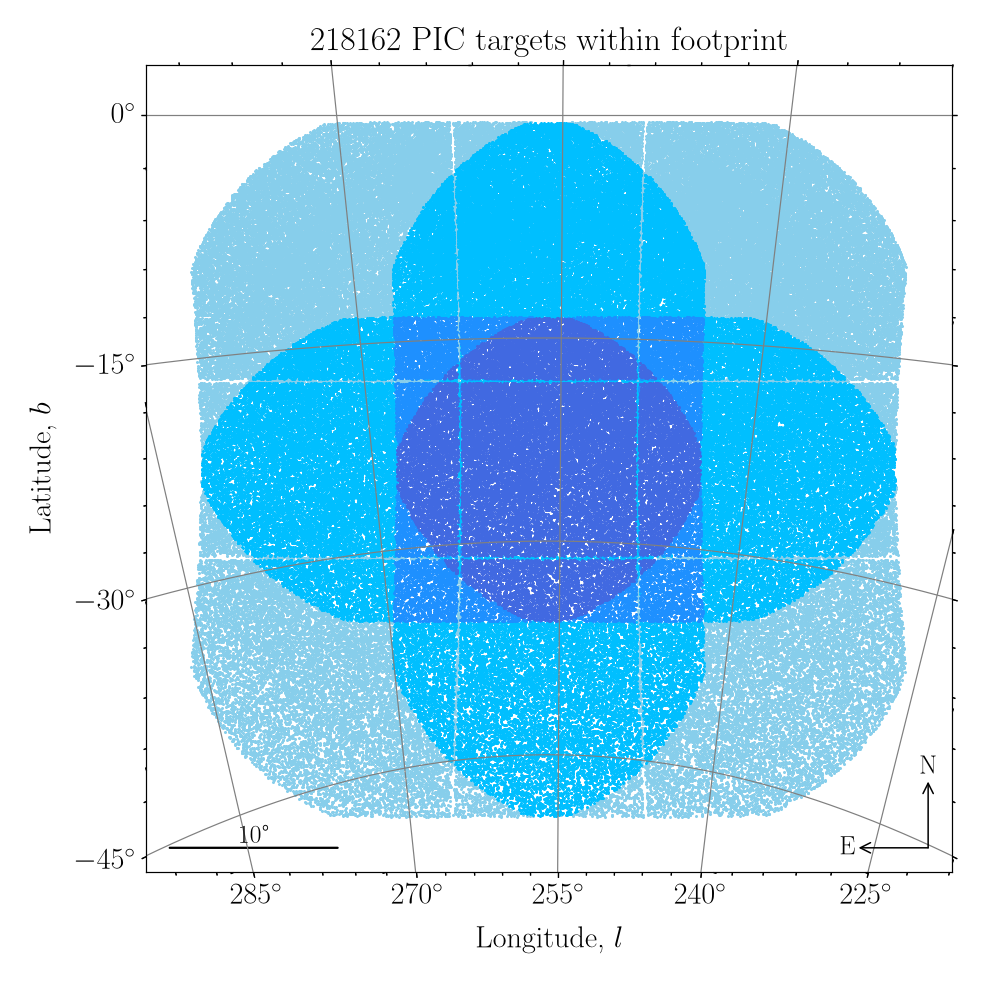

In [130]:
dx = dt[(dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dx,
    # Settings
    figsize=(9,9), title=f'{dx.shape[0]} PIC targets within footprint'
)

---
### Plots for tPIC

Plot `tPIC` targets:

<IPython.core.display.Javascript object>


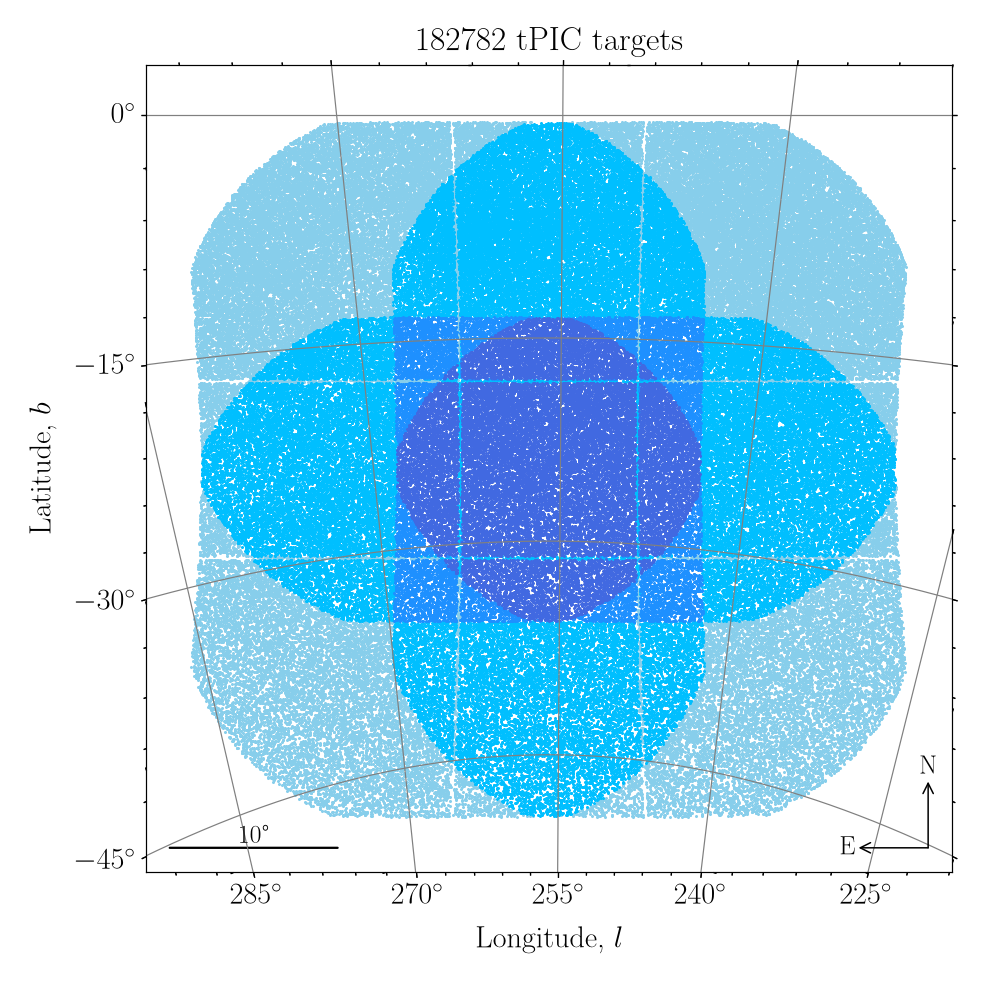

In [174]:
dx = dt[(dt['source'] & 4 == 4) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dx,
    # Settings
    figsize=(9,9), title=f'{dx.shape[0]} tPIC targets'
)

Plot all `P1` targets and their planets (candidates):

<IPython.core.display.Javascript object>


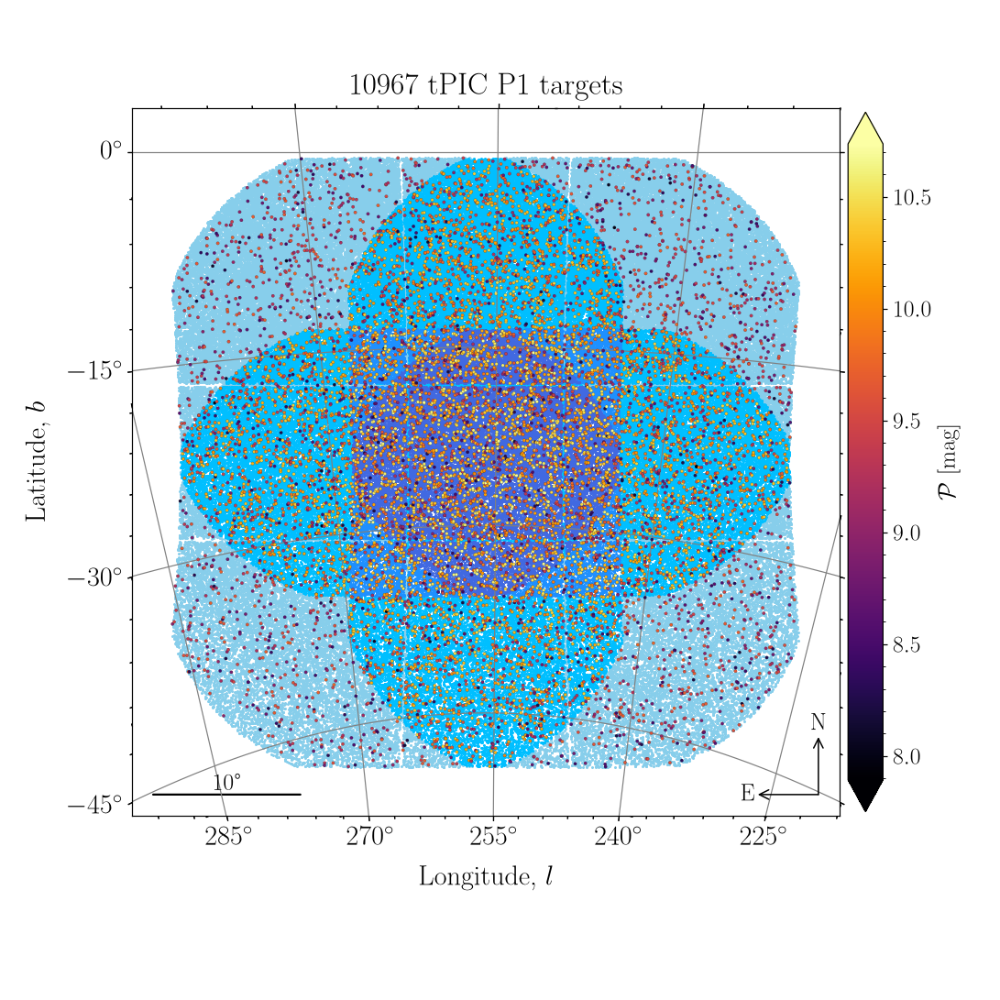

In [132]:
dx = dt[(dt.tPIC == 1) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=20, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P1 targets'
)

Plot `P1` targets with planets (candidates):

<IPython.core.display.Javascript object>


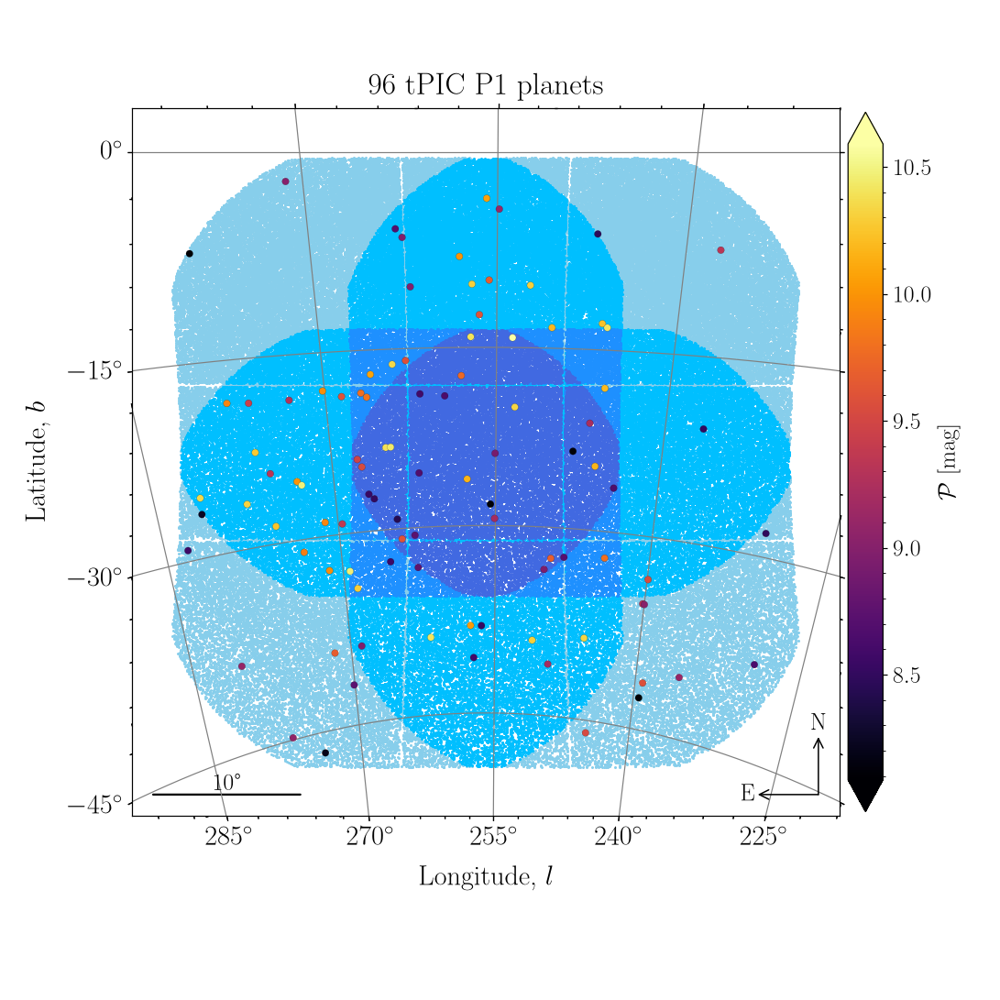

In [134]:
dx = dt[(dt.tPIC == 17) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P1 planets'
)

Plot all `P2` targets and their planets (candidates):

<IPython.core.display.Javascript object>


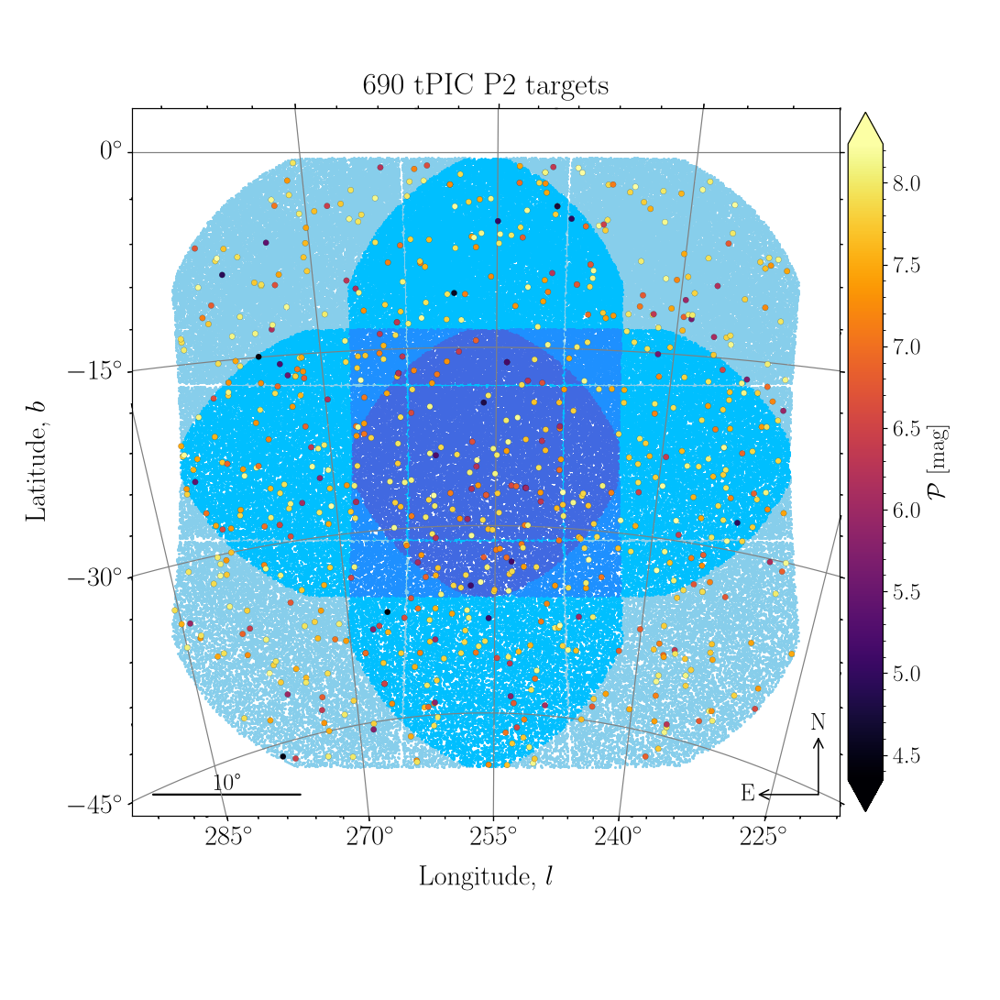

In [135]:
dx = dt[(dt.tPIC == 3) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=70, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P2 targets'
)

<IPython.core.display.Javascript object>


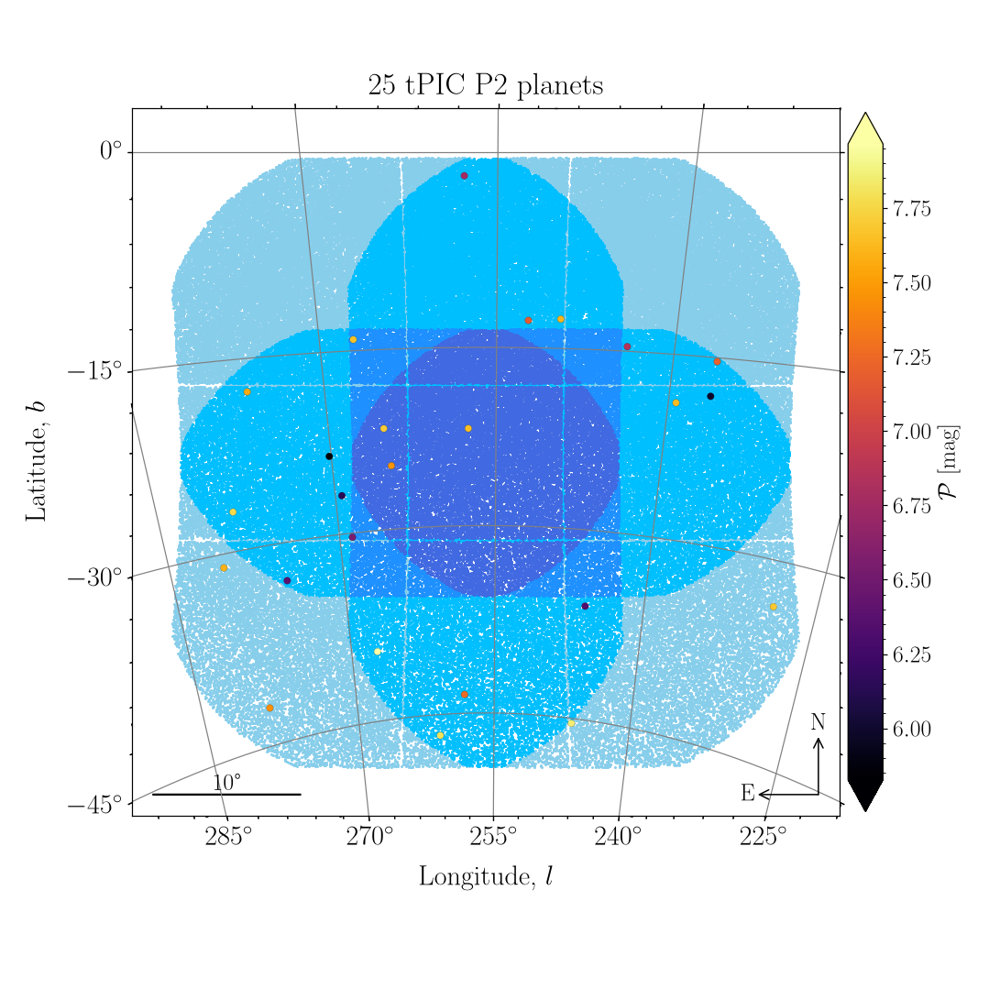

In [137]:
dx = dt[(dt.tPIC == 19) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P2 planets'
)

Plot all `P4` targets and their planets (candidates):

<IPython.core.display.Javascript object>


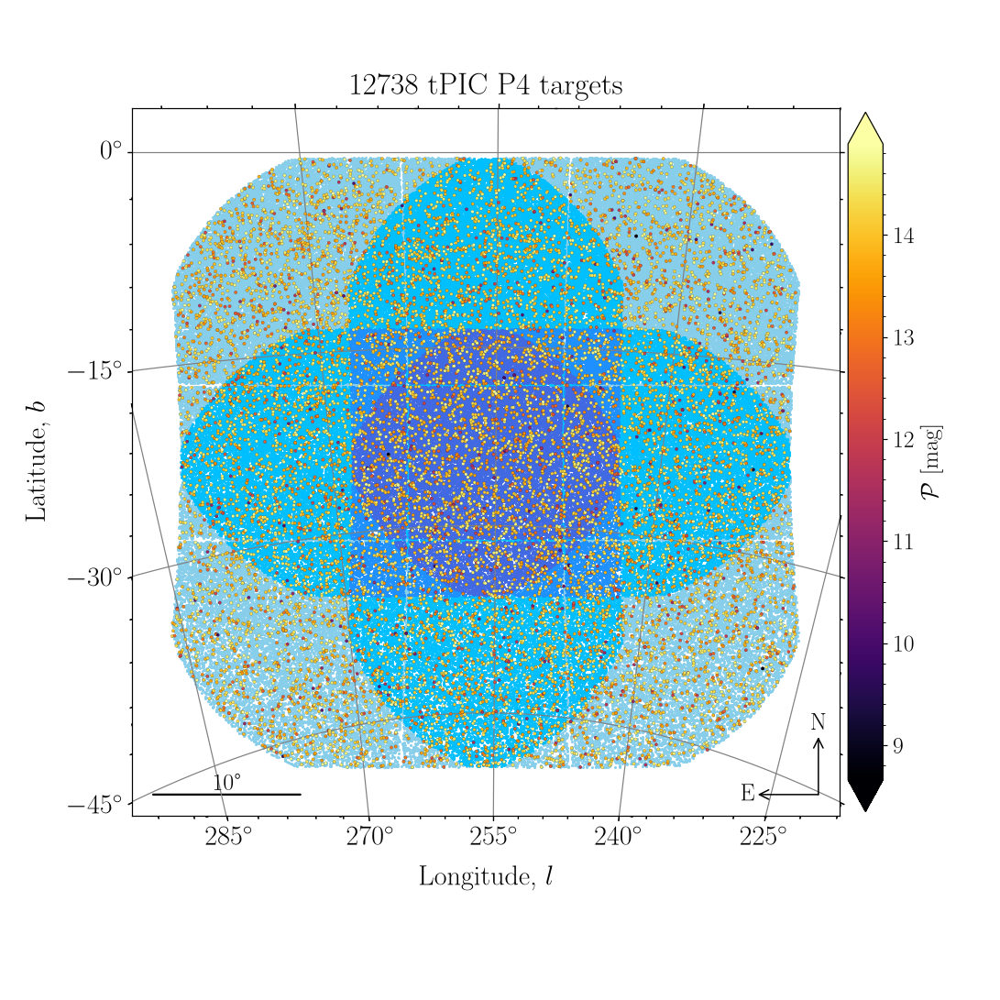

In [139]:
dx = dt[(dt.tPIC == 8) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=20, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P4 targets'
)

<IPython.core.display.Javascript object>


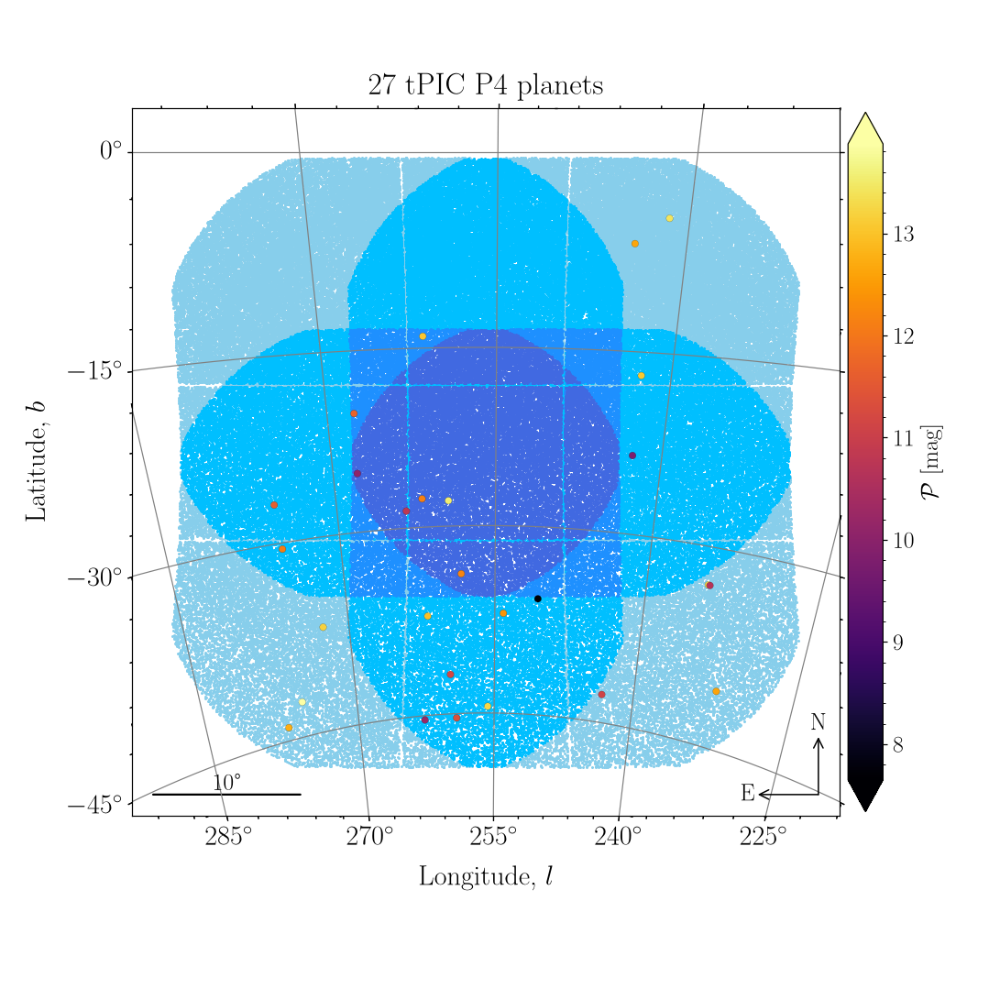

In [140]:
dx = dt[(dt.tPIC == 24) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P4 planets'
)

Plot all `P5` targets and their planets (candidates):

<IPython.core.display.Javascript object>


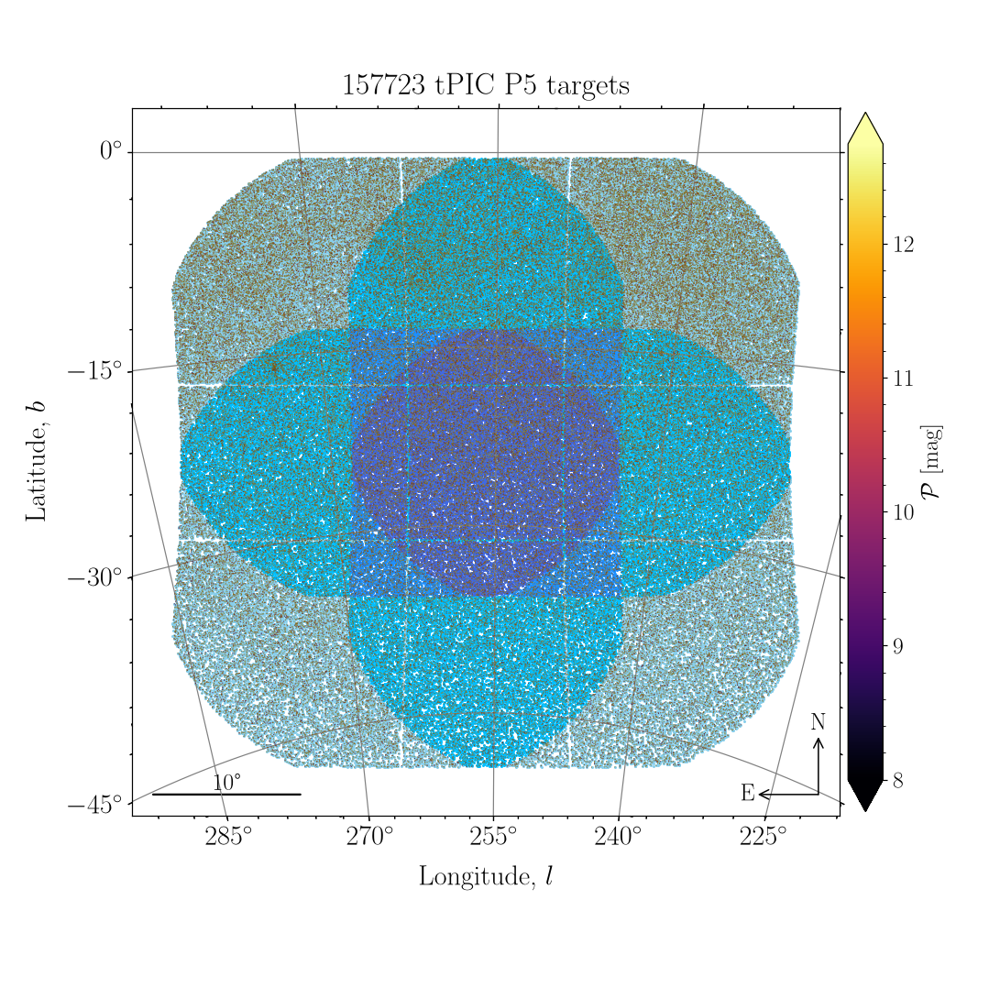

In [141]:
dx = dt[(dt.tPIC == 4) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=1.5, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P5 targets'
)

<IPython.core.display.Javascript object>


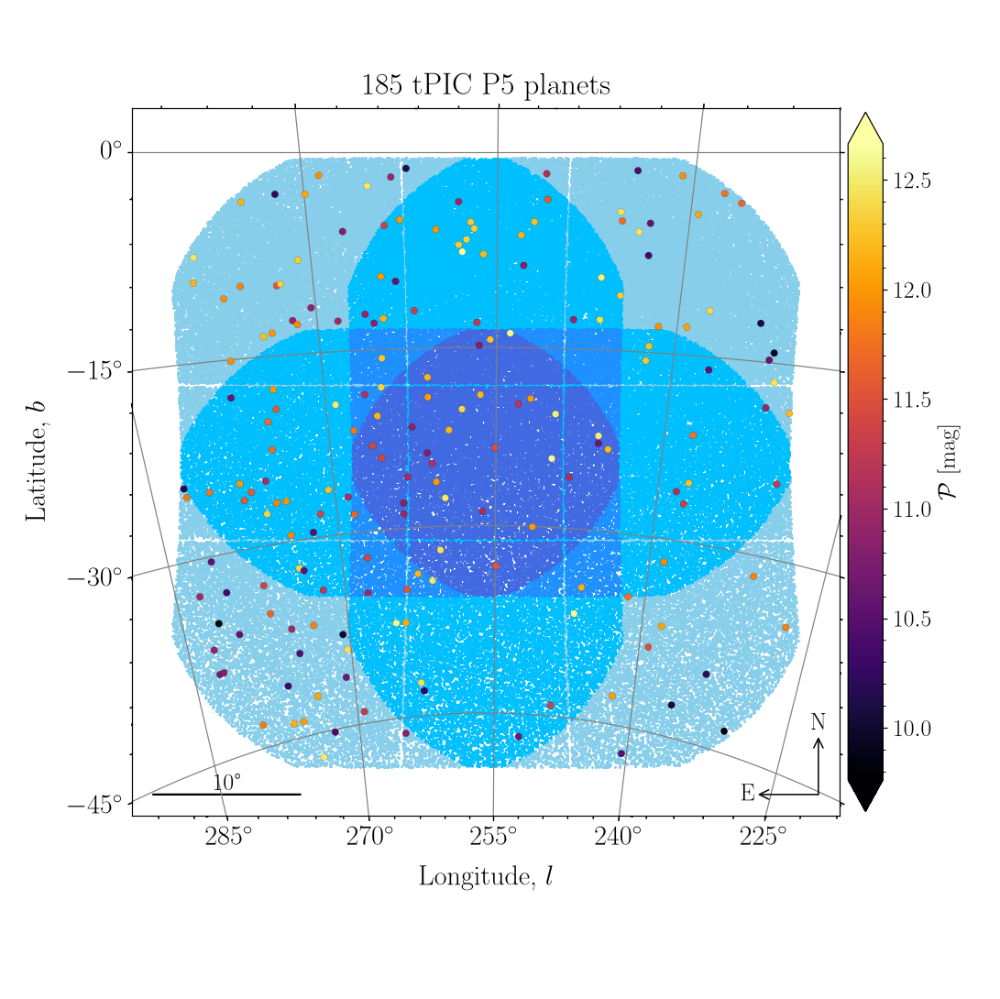

In [142]:
dx = dt[(dt.tPIC == 20) & (dt.ncams != 0)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} tPIC P5 planets'
)

---
### Plots for fgPIC

Plot `fgPIC` targets:

<IPython.core.display.Javascript object>


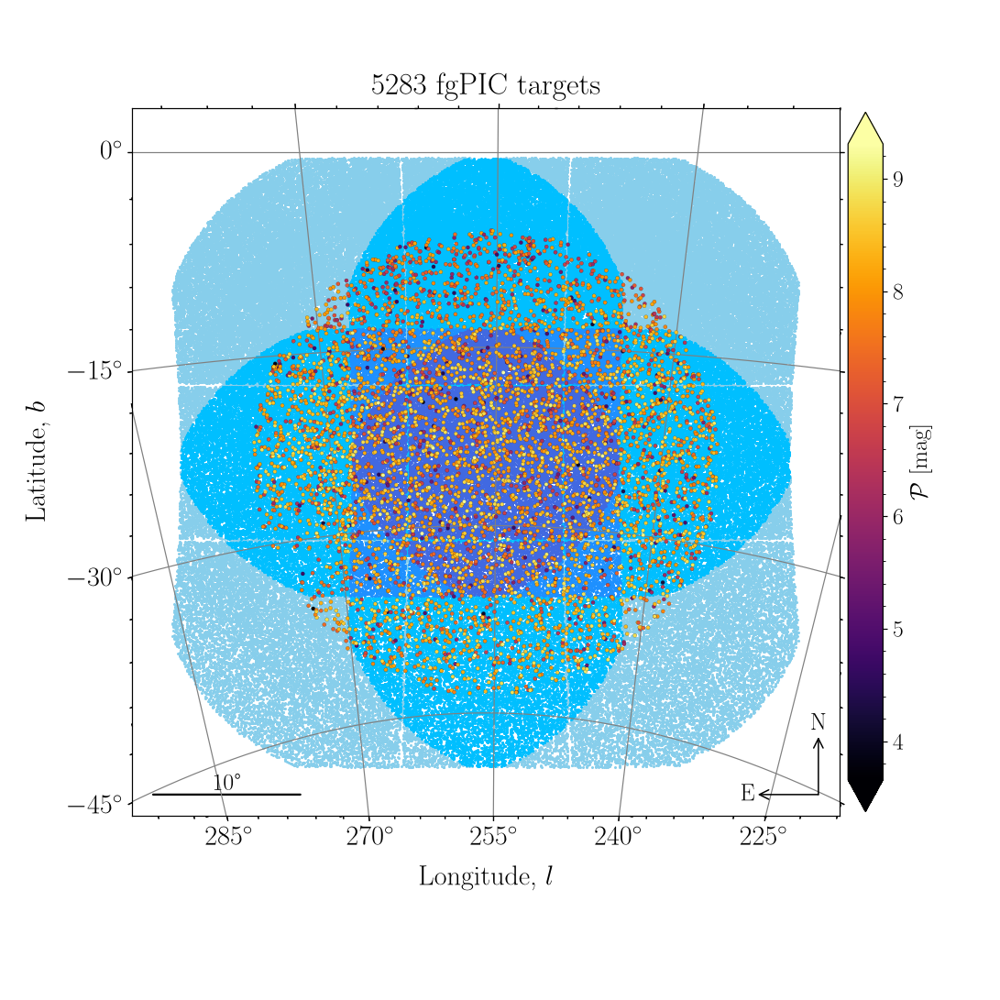

In [143]:
dx = dt.loc[dt.source & 8 == 8]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} fgPIC targets'
)

Plot fgPIC `F-CAMb` targets:

<IPython.core.display.Javascript object>


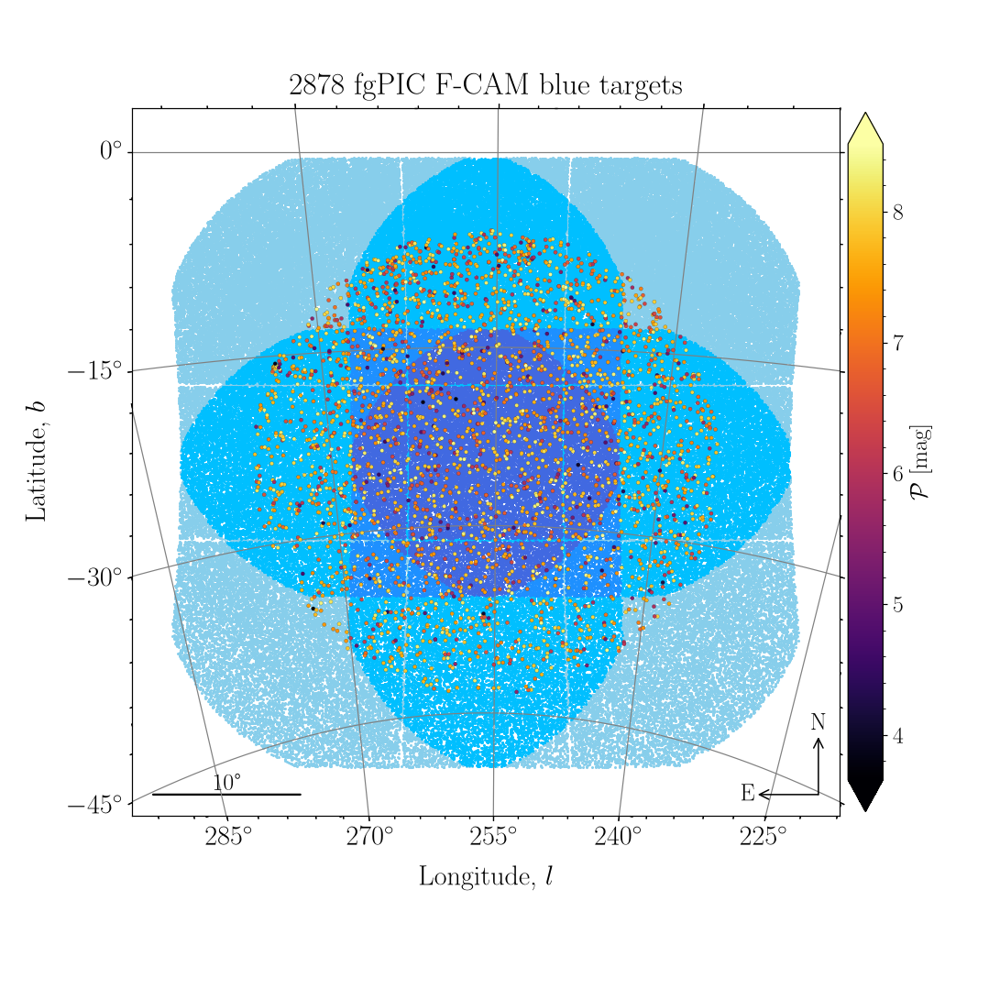

In [144]:
dx = dt.loc[dt.fgPIC & 1 == 1]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} fgPIC F-CAM blue targets'
)

Plot fgPIC `F-CAMr` targets:

<IPython.core.display.Javascript object>


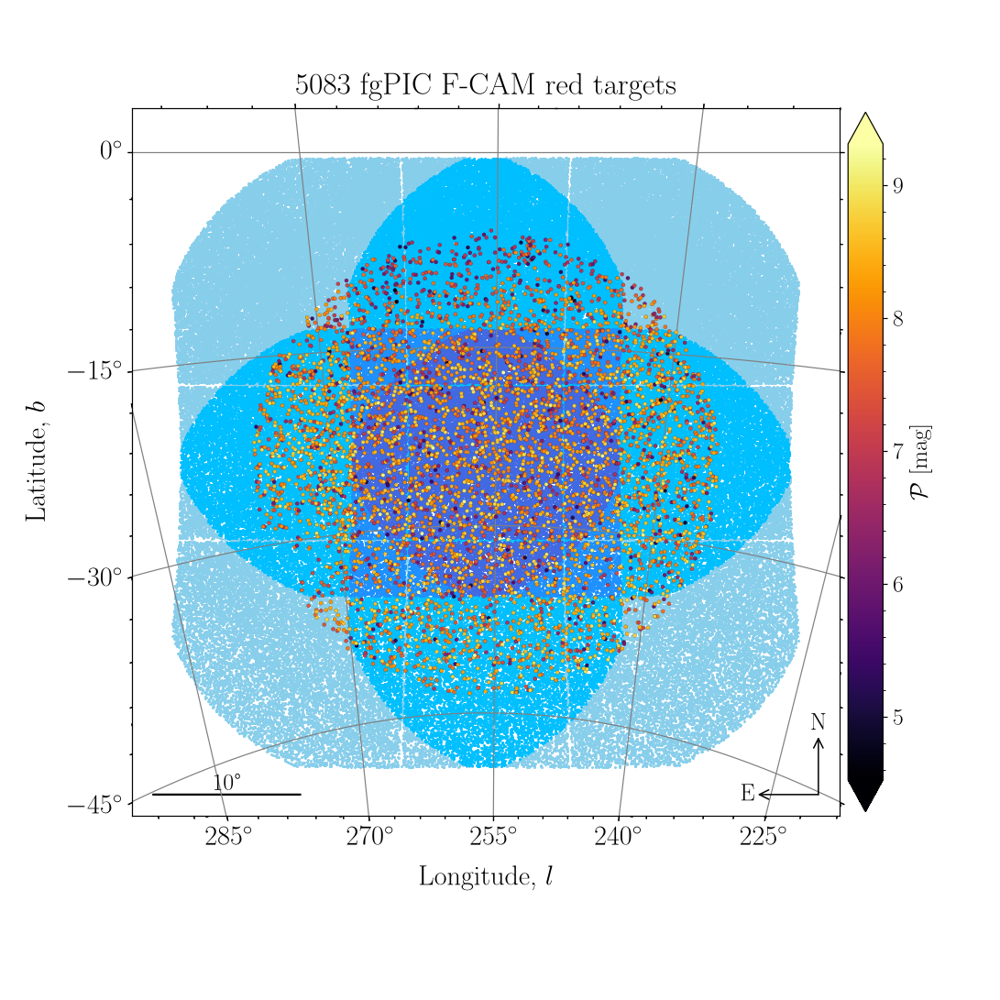

In [145]:
dx = dt.loc[dt.fgPIC & 2 == 2]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} fgPIC F-CAM red targets'
)

---
### Plots for cPIC

Plot `cPIC` targets:

<IPython.core.display.Javascript object>


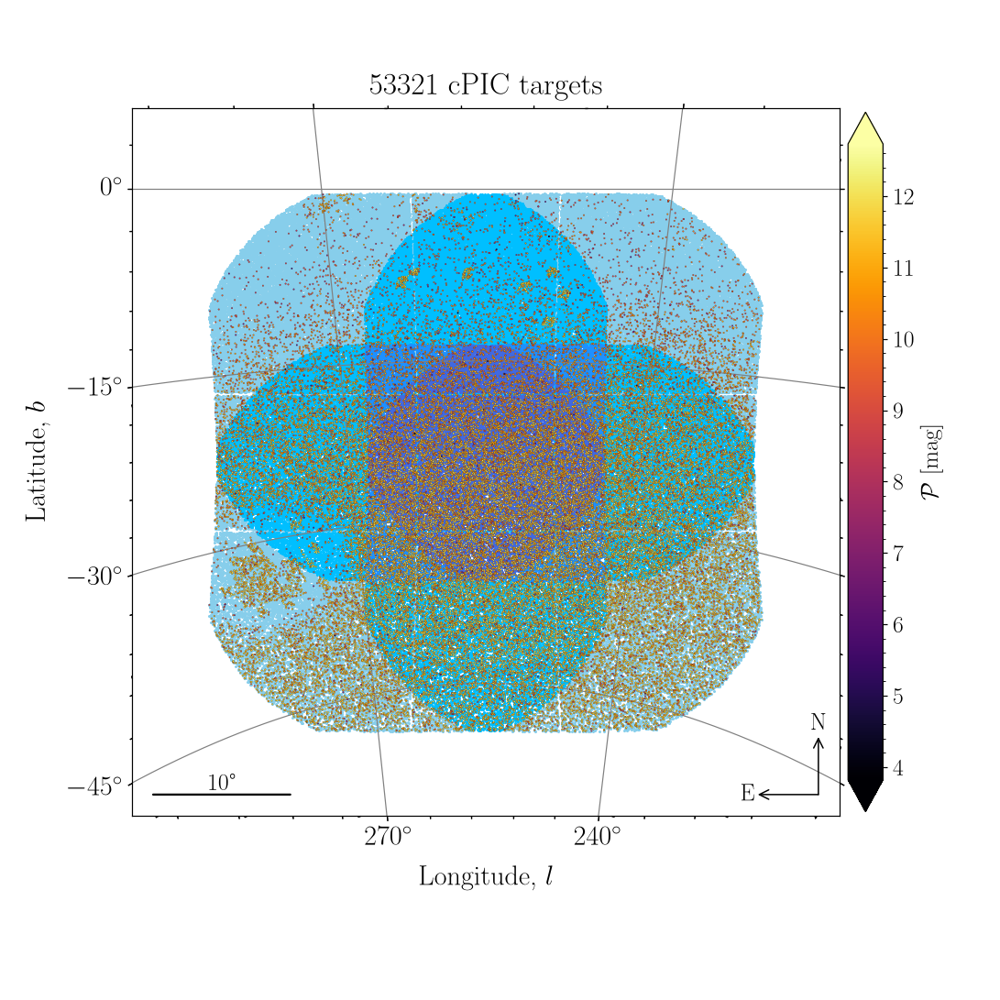

In [148]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['source'] & 16 == 16]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=34, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=5, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC targets'
)

Plot cPIC `F-CAM R1` sample:

<IPython.core.display.Javascript object>


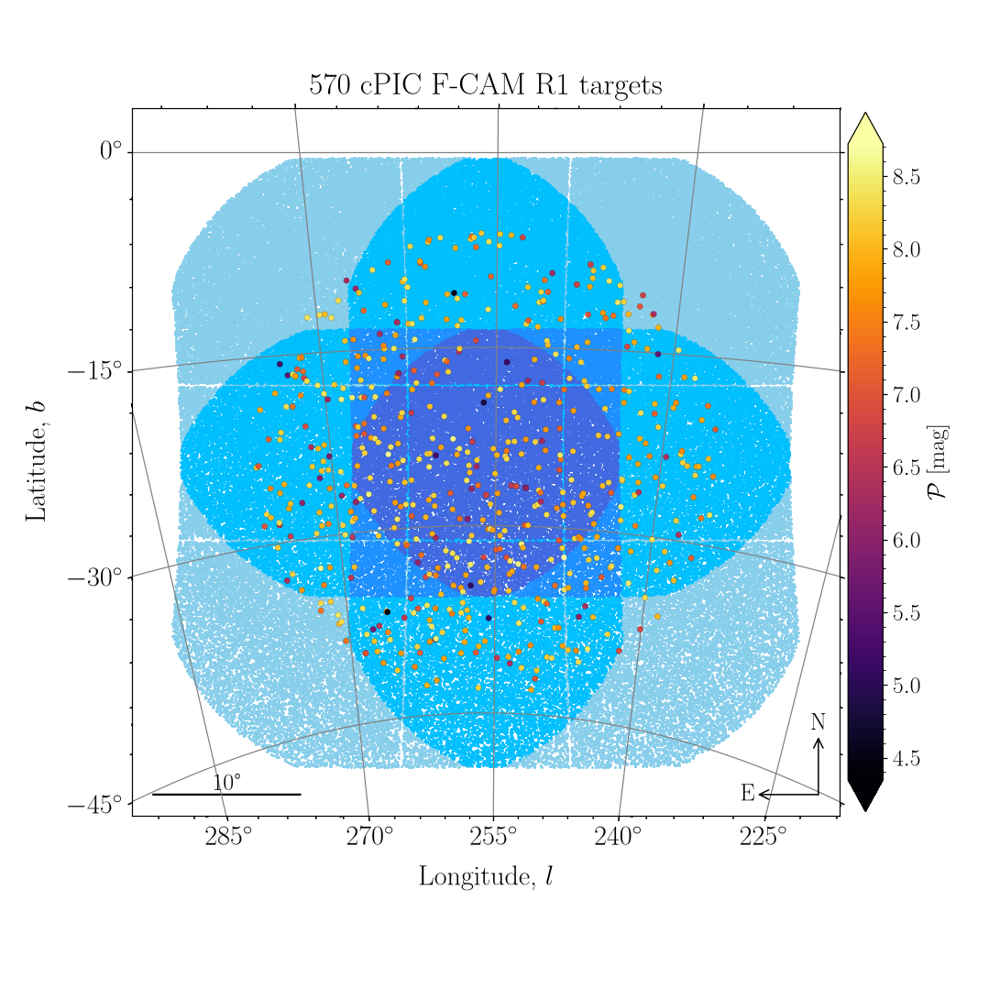

In [149]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 1 == 1]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=70, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R1 targets'
)

Plot cPIC `F-CAM R2` sample:

<IPython.core.display.Javascript object>


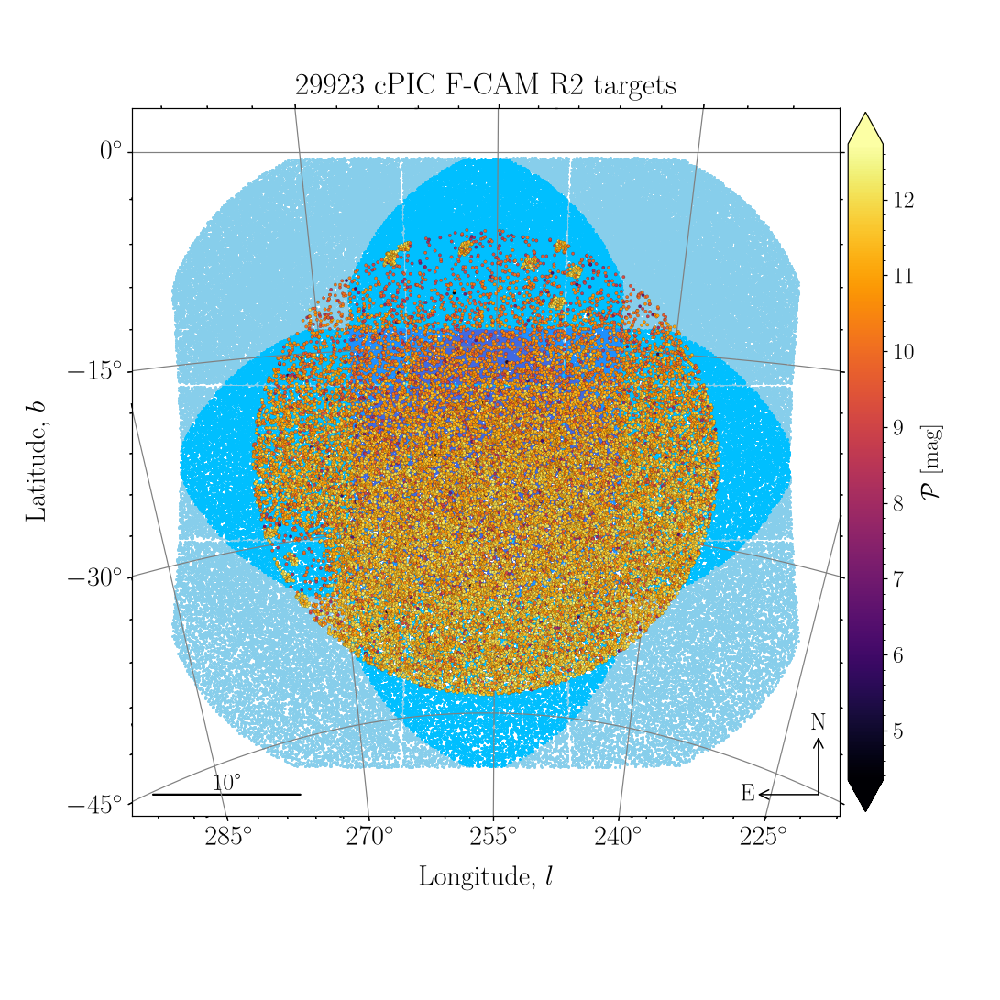

In [150]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 2 == 2]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=20, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R2 targets'
)

Plot cPIC `F-CAM R3` sample:

<IPython.core.display.Javascript object>


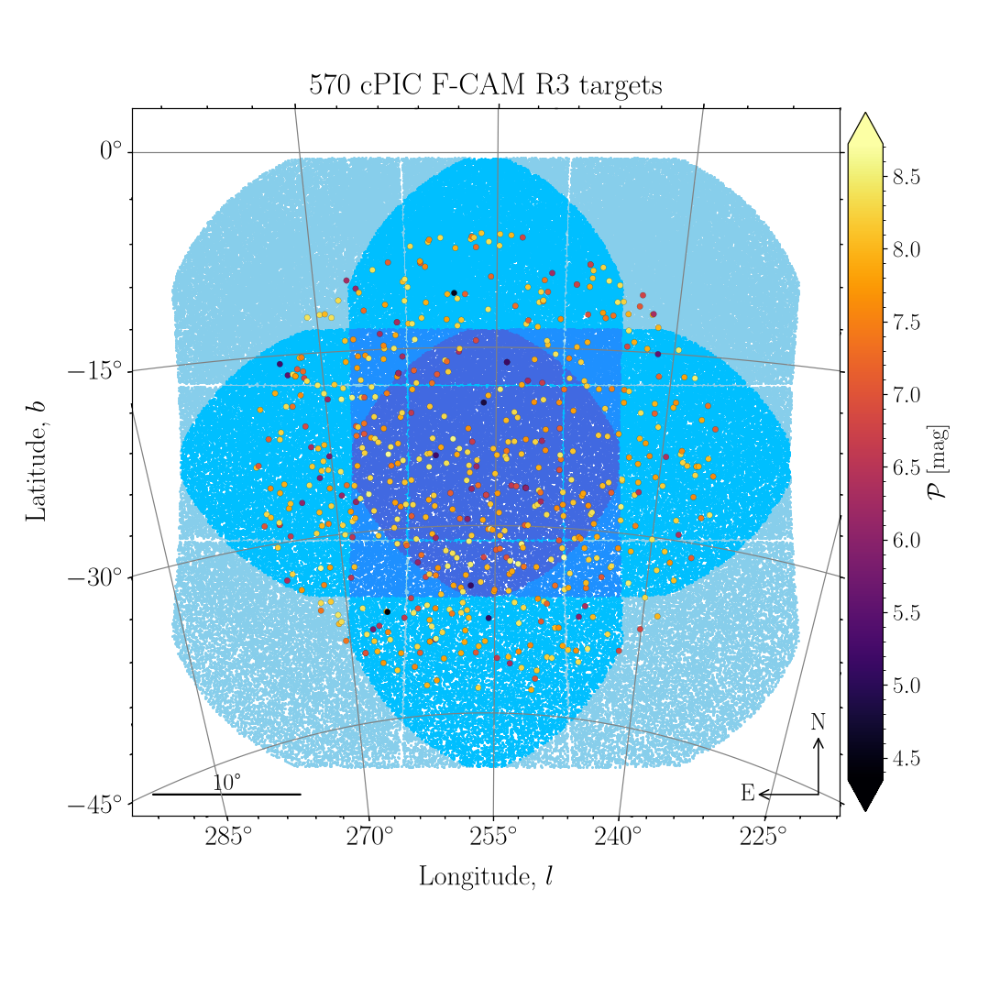

In [151]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 4 == 4]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=70, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R3 targets'
)

Plot `cPIC F-CAM R4` sample:

<IPython.core.display.Javascript object>


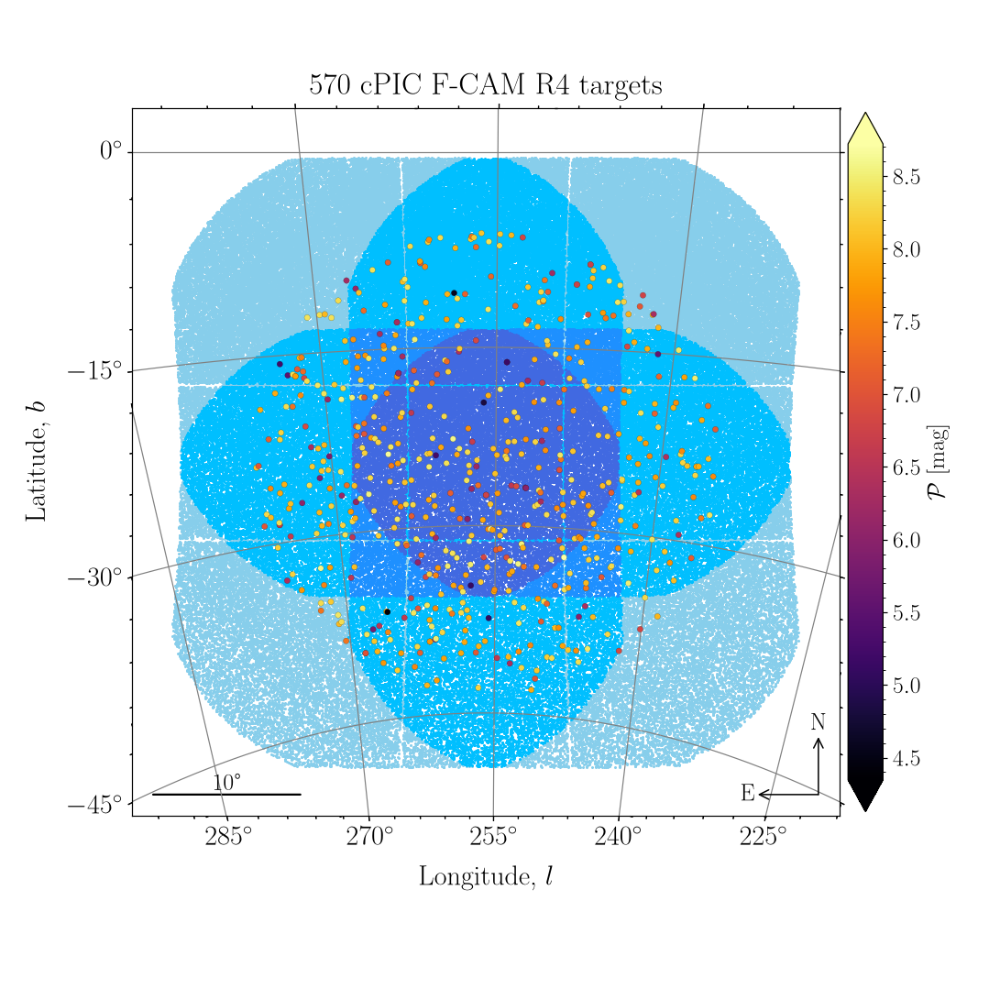

In [152]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 8 == 8]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=70, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R4 targets'
)

Plot cPIC `F-CAM R5` sample:

<IPython.core.display.Javascript object>


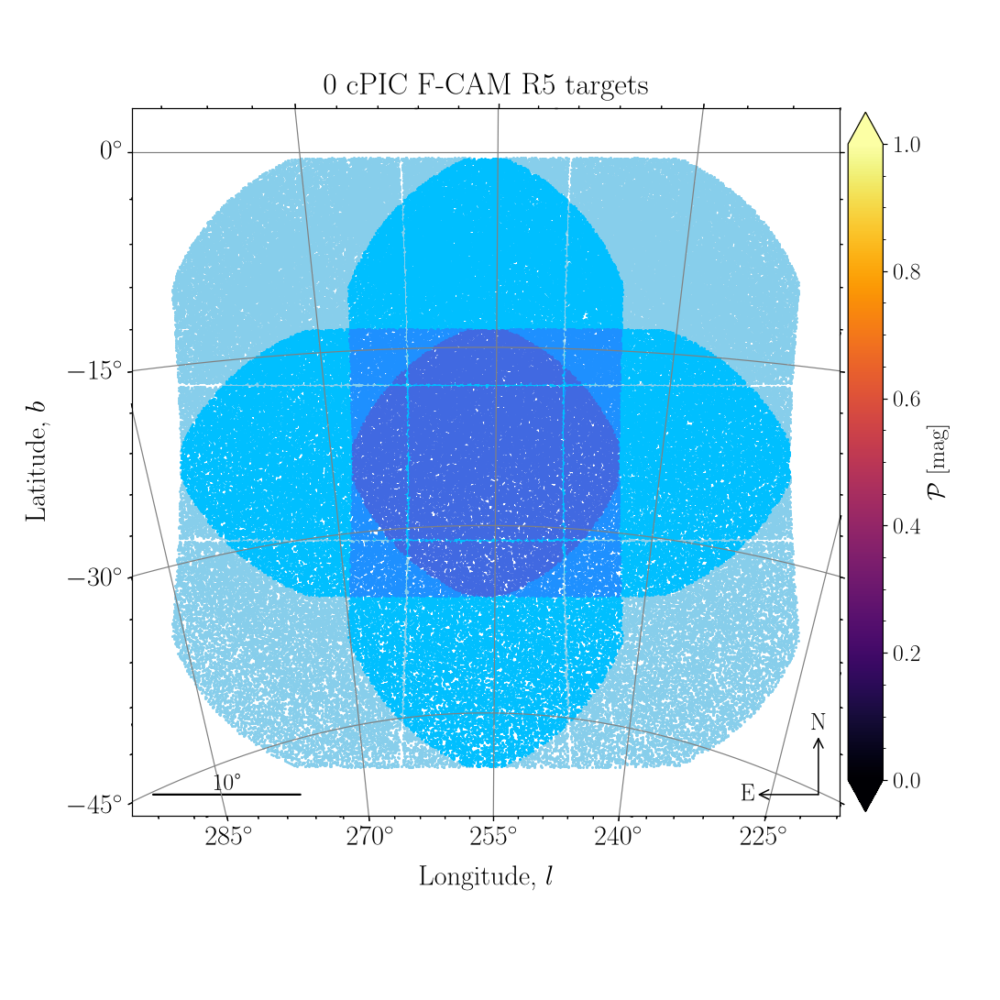

In [153]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 16 == 16]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=70, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC F-CAM R5 targets'
)

Plot cPIC `N-CAM R1` sample:

<IPython.core.display.Javascript object>


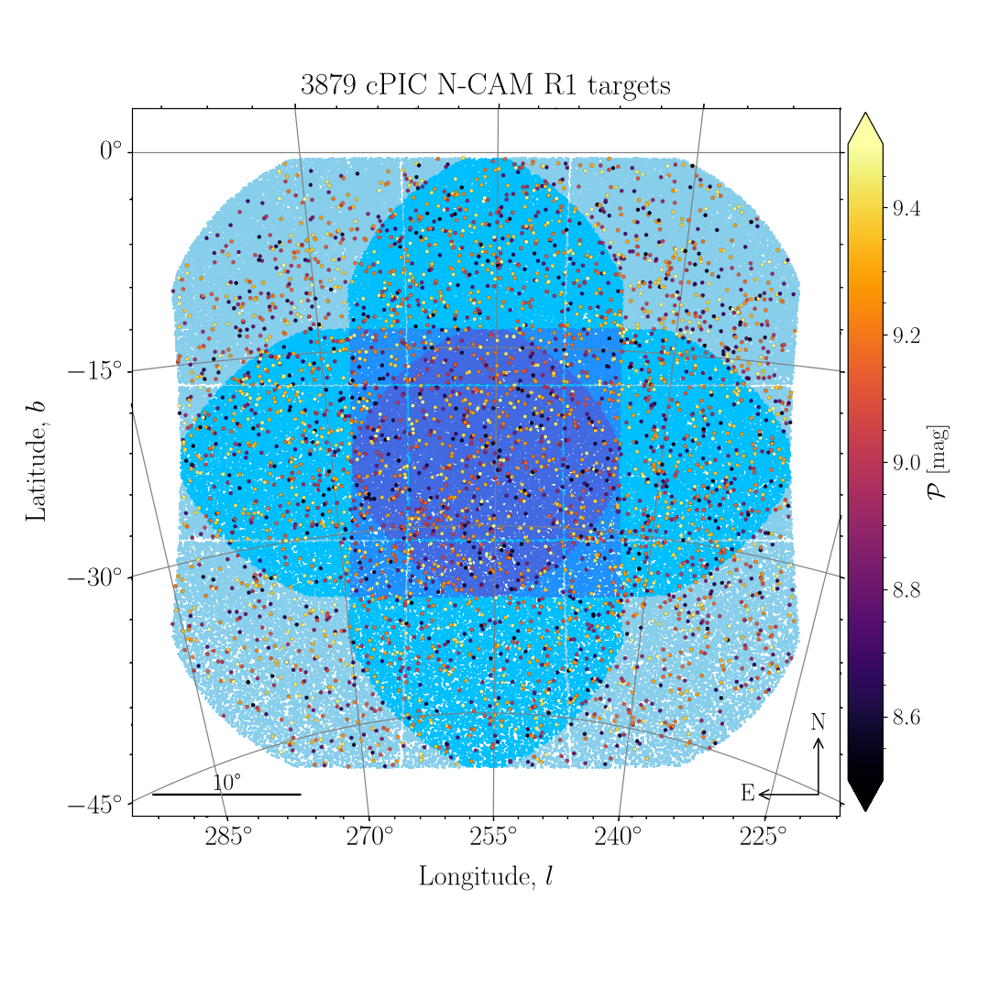

In [154]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 32 == 32]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R1 targets'
)

Plot cPIC `N-CAM R2` sample:

<IPython.core.display.Javascript object>


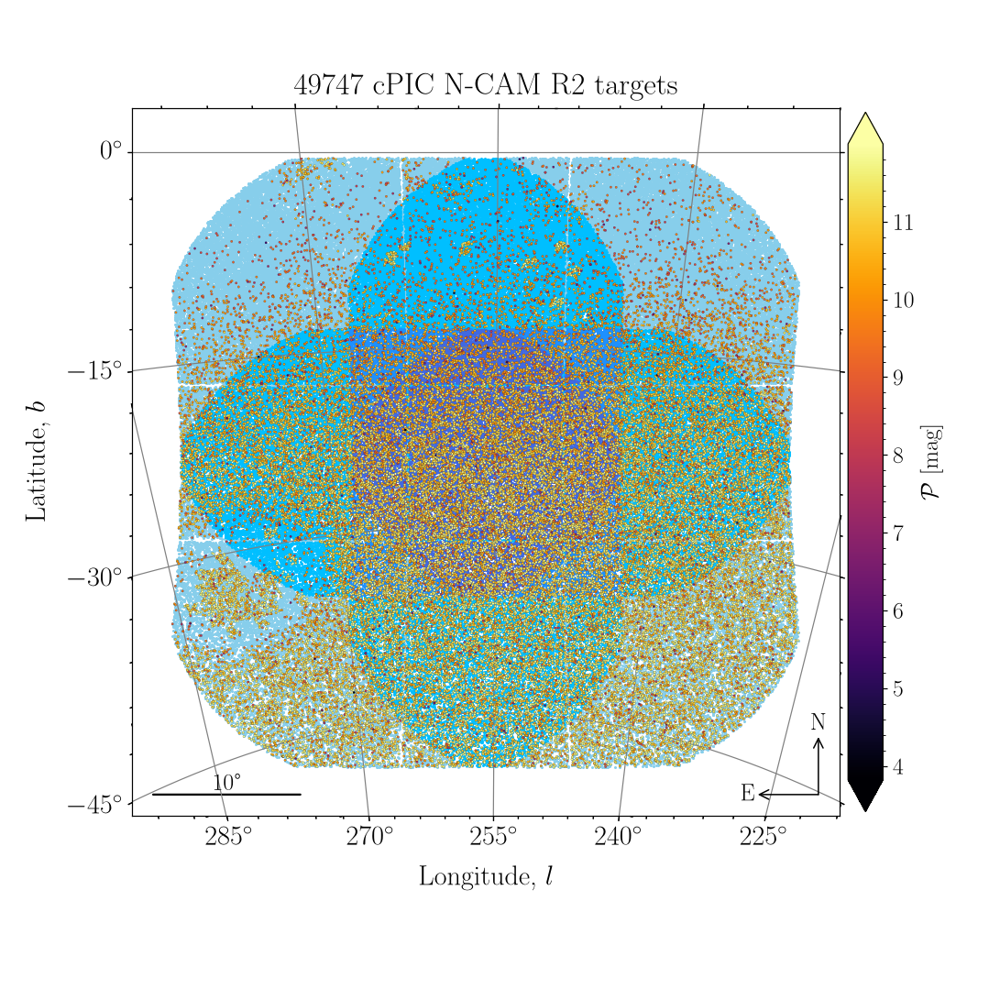

In [155]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 64 == 64]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=10, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R2 targets'
)

Plot cPIC `N-CAM R3` sample:

<IPython.core.display.Javascript object>


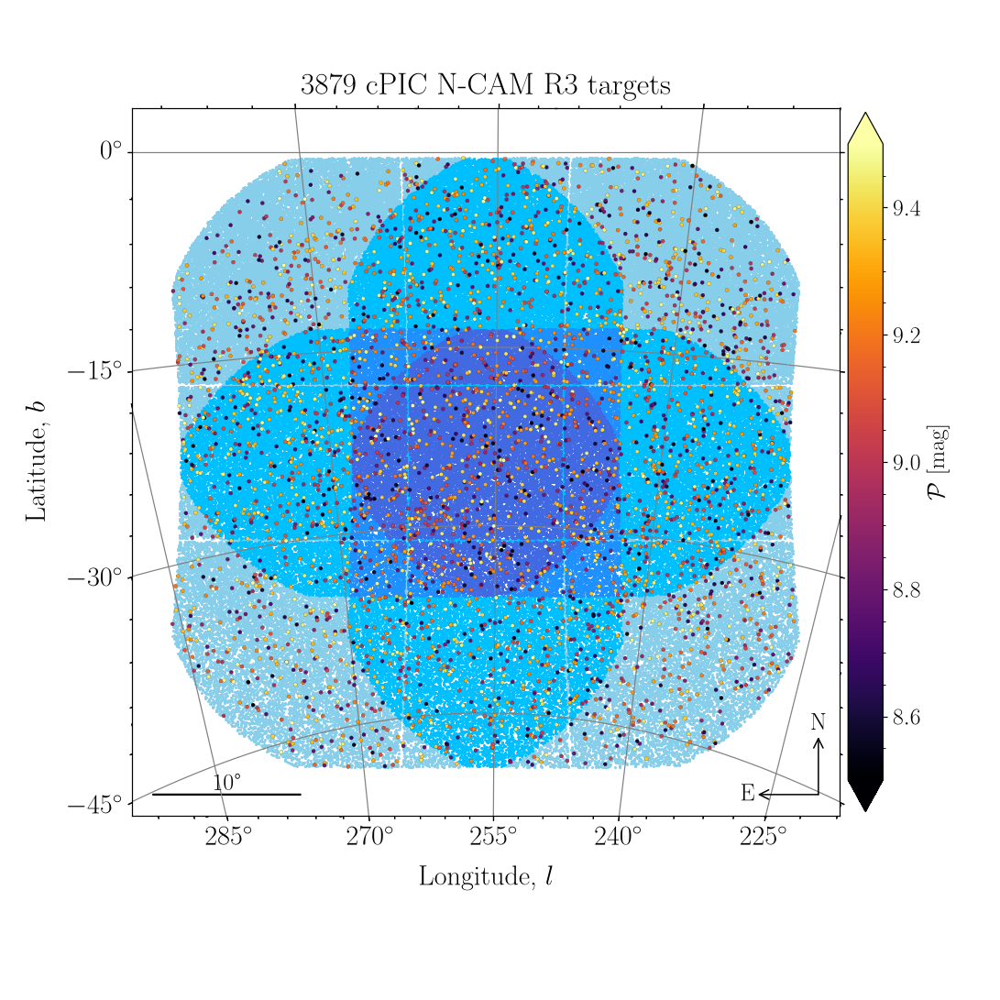

In [156]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 128 == 128]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R3 targets'
)

Plot cPIC `N-CAM R4` sample:

<IPython.core.display.Javascript object>


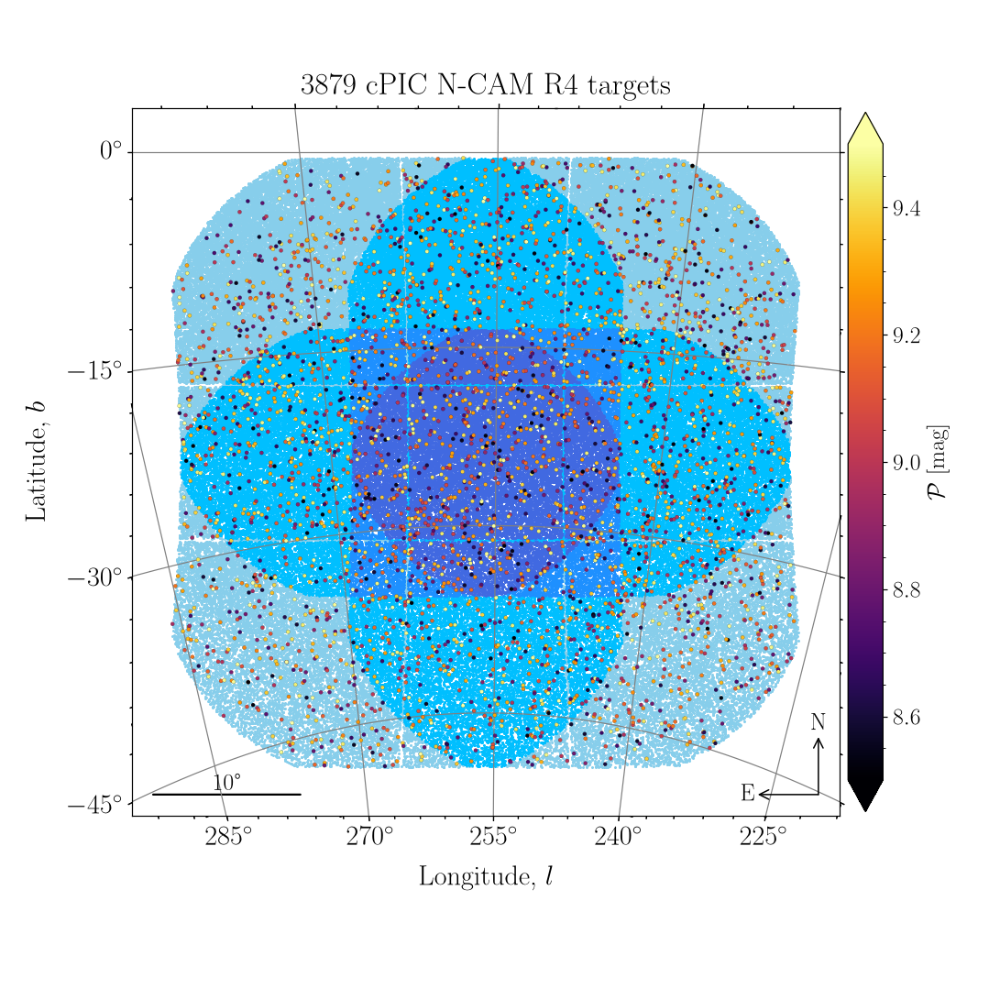

In [157]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 256 == 256]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R4 targets'
)

Plot cPIC `N-CAM R5` sample:

<IPython.core.display.Javascript object>


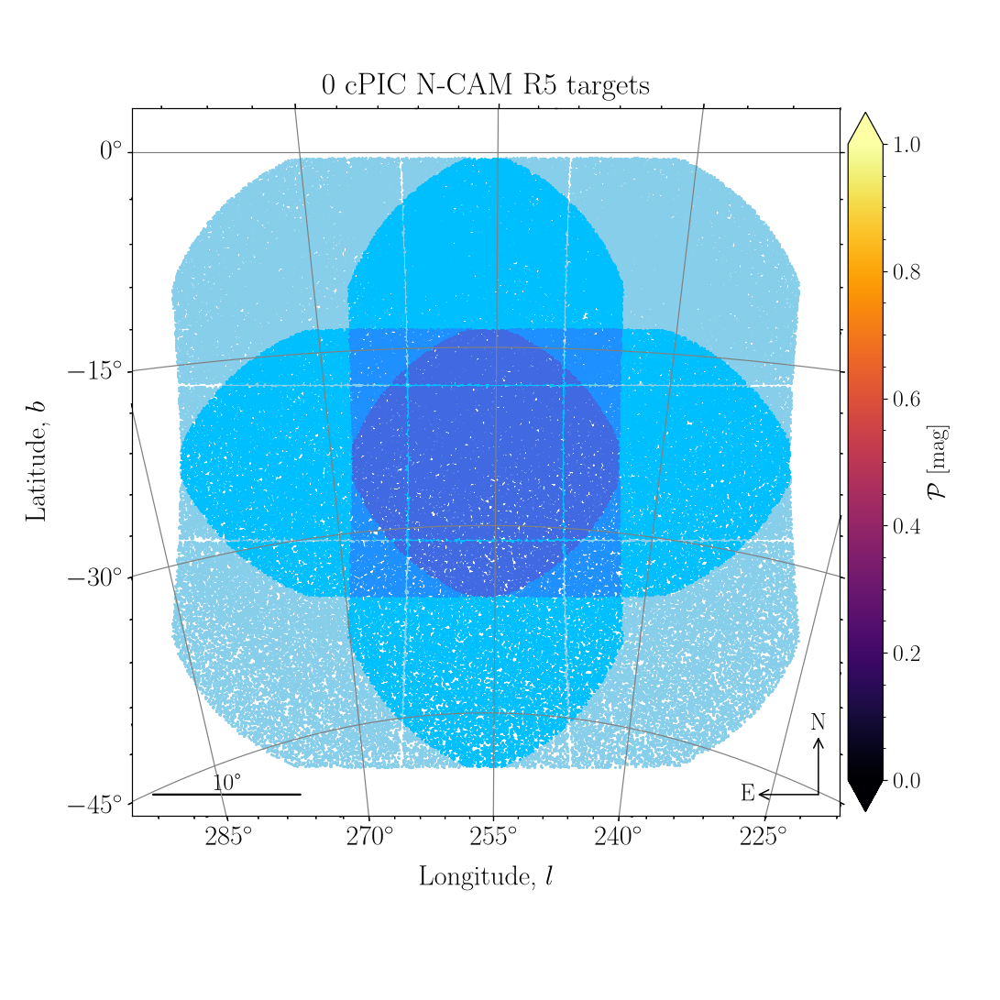

In [158]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['cPIC'] & 512 == 512]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=70, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} cPIC N-CAM R5 targets'
)

---
### Plots for scvPIC

Plot `scvPIC` targets:

<IPython.core.display.Javascript object>


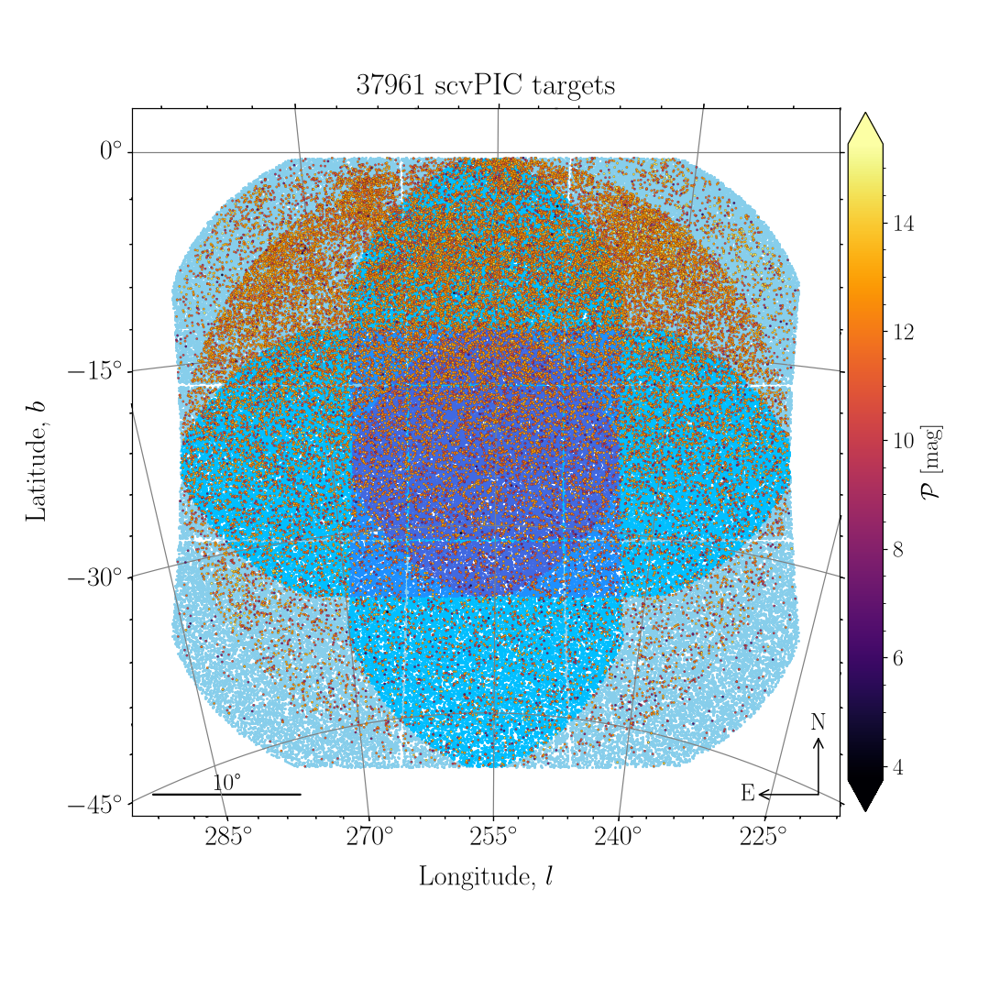

In [159]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['source'] & 32 == 32]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=10, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} scvPIC targets'
)
fig.savefig('skymap_LOPS2_scvPIC2101.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV1a` sample (eclipsing binaries):

<IPython.core.display.Javascript object>


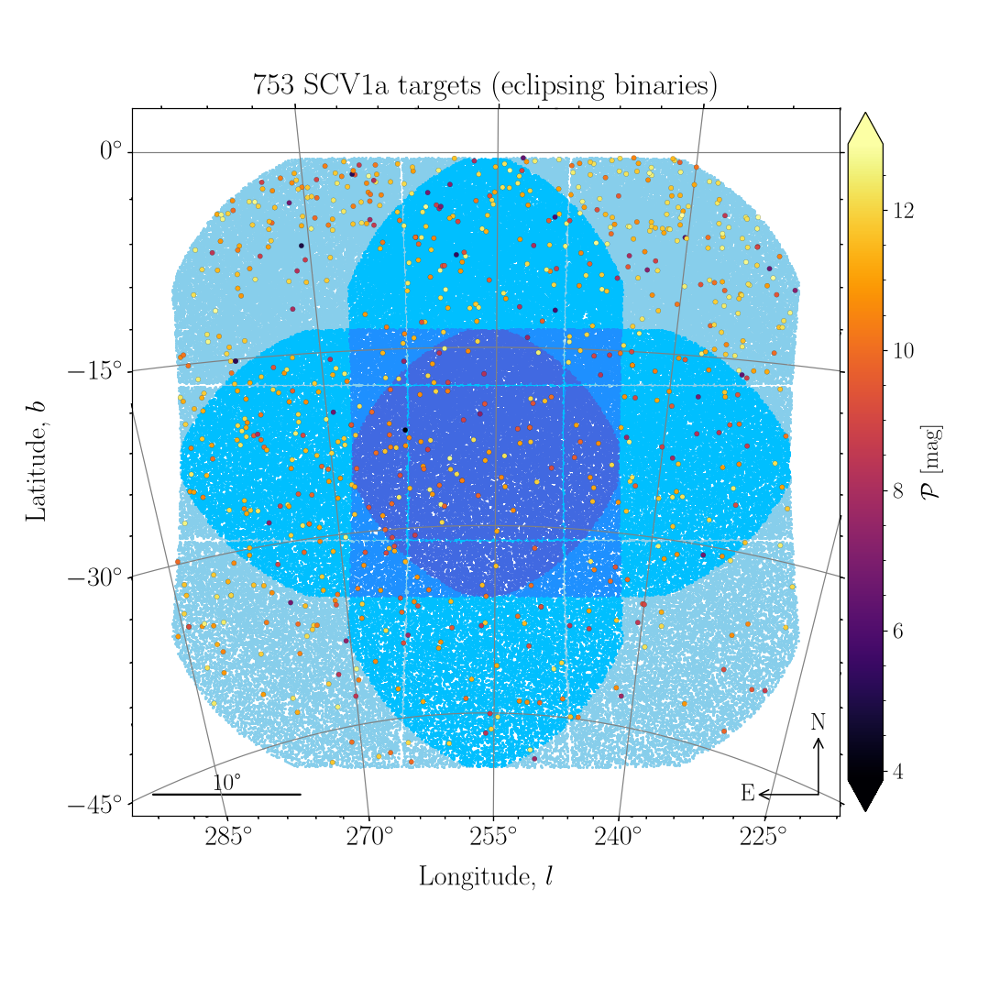

In [160]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 1 == 1]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=50, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV1a targets (eclipsing binaries)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV1a.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV1b` sample (astrometric binaries):

<IPython.core.display.Javascript object>


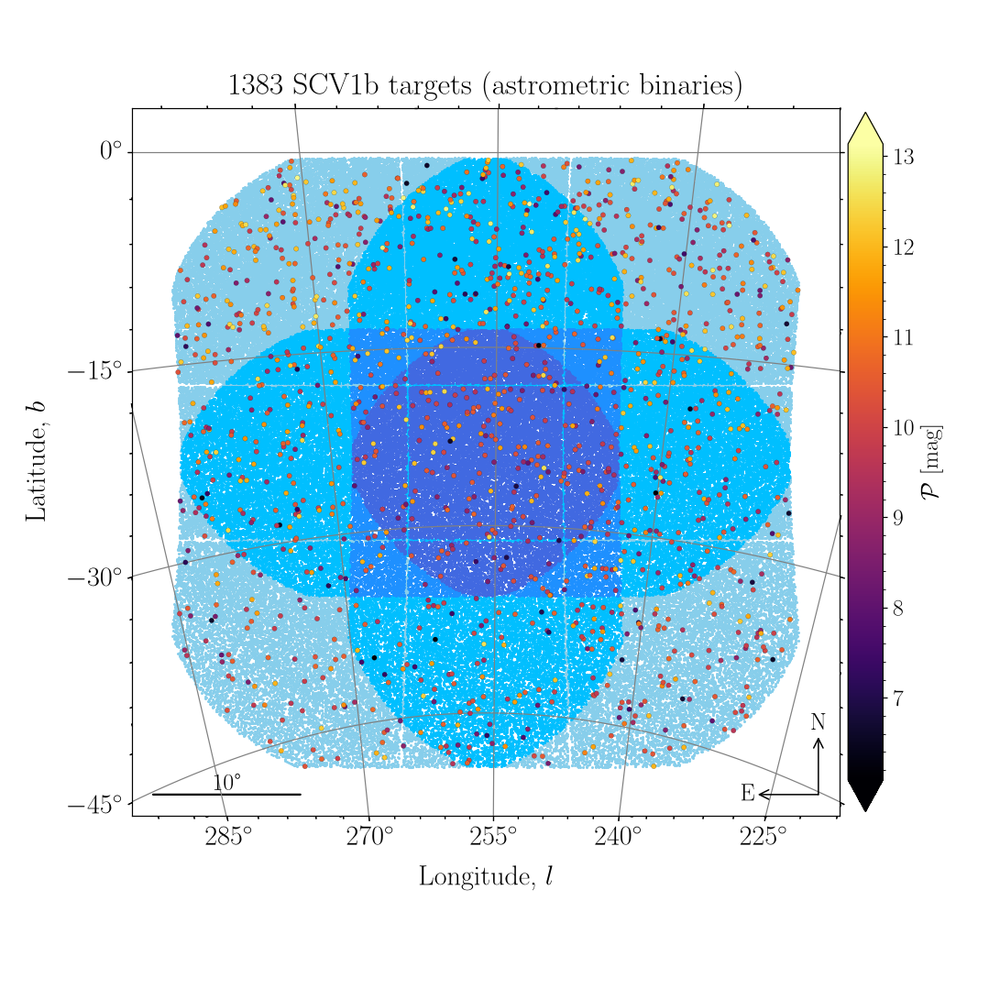

In [161]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 2 == 2]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=50, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV1b targets (astrometric binaries)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV1b.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV1c` sample (wide binaries):

<IPython.core.display.Javascript object>


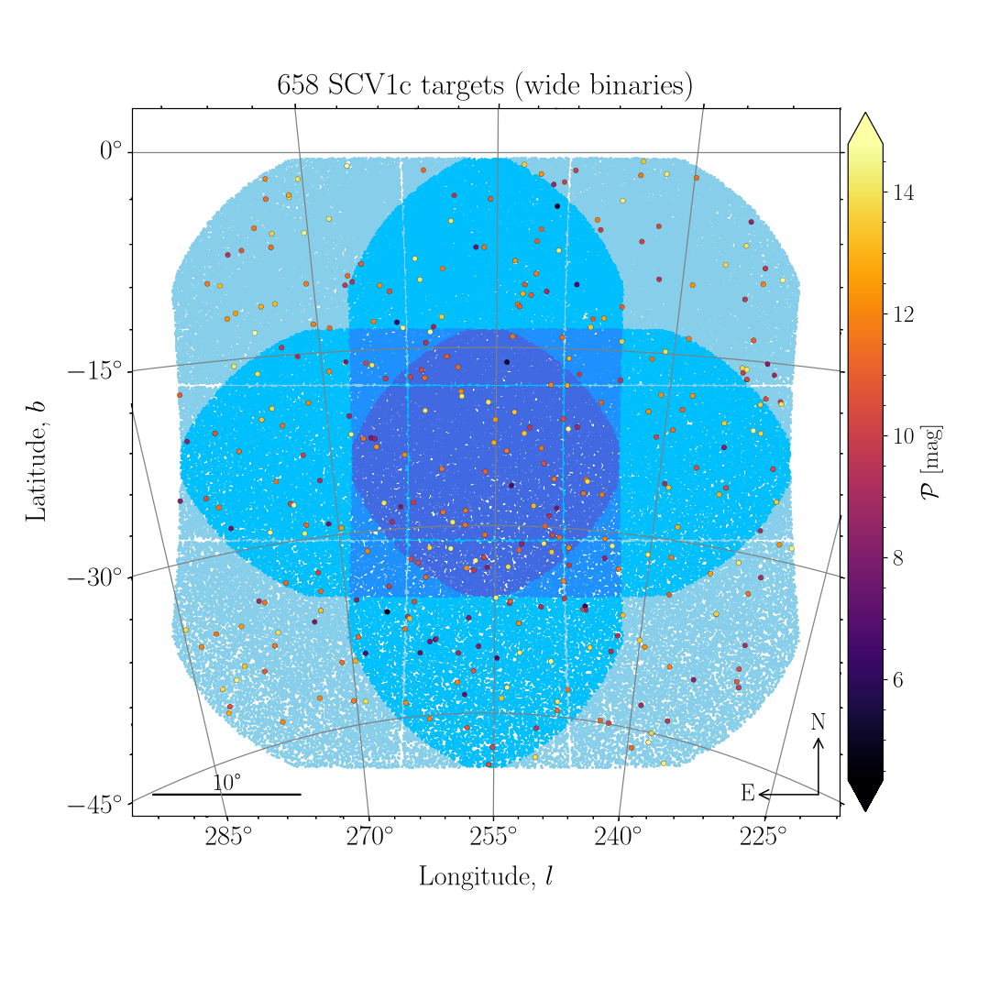

In [162]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 4 == 4]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=50, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV1c targets (wide binaries)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV1c.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV1d` sample (HW Vir-type binaries):

<IPython.core.display.Javascript object>


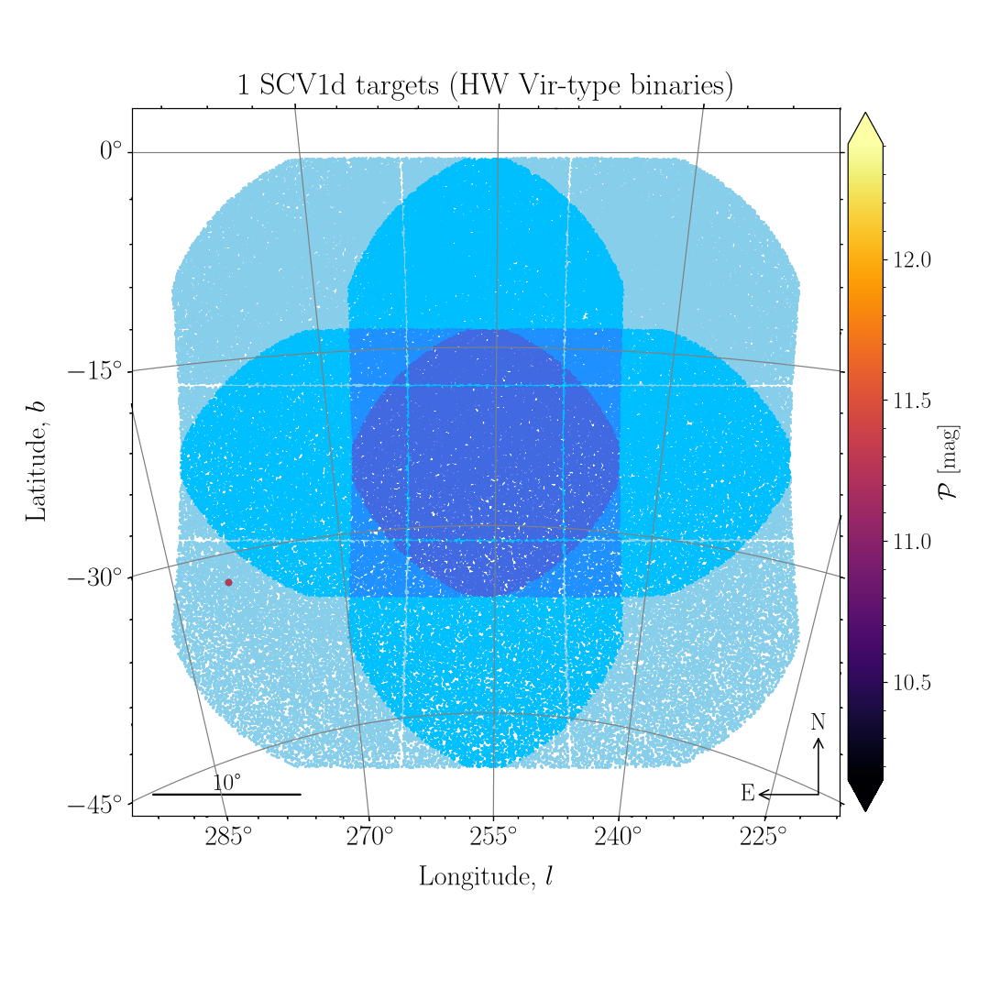

In [163]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 8 == 8]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV1d targets (HW Vir-type binaries)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV1d.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV1e` sample (wide WD binaries):

<IPython.core.display.Javascript object>


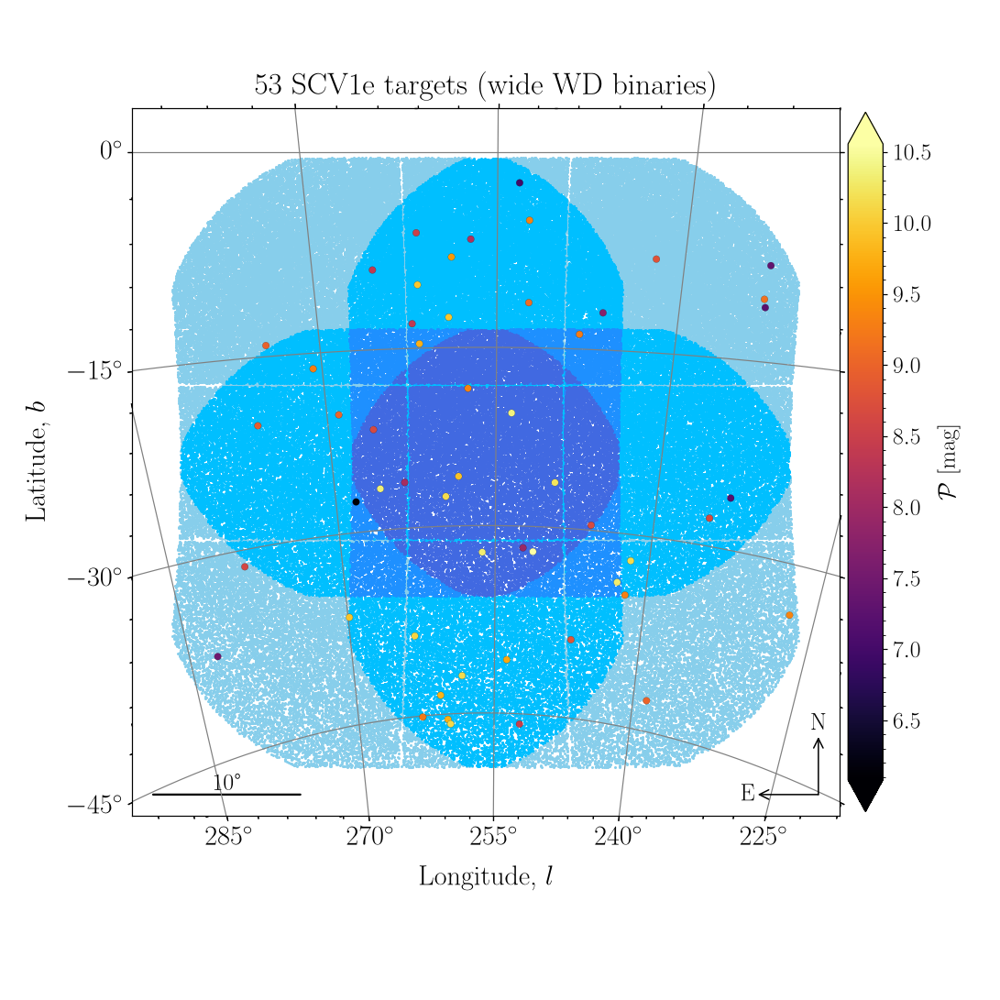

In [164]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 16 == 16]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV1e targets (wide WD binaries)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV1e.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV2a` sample (legacy and benchmark):

<IPython.core.display.Javascript object>


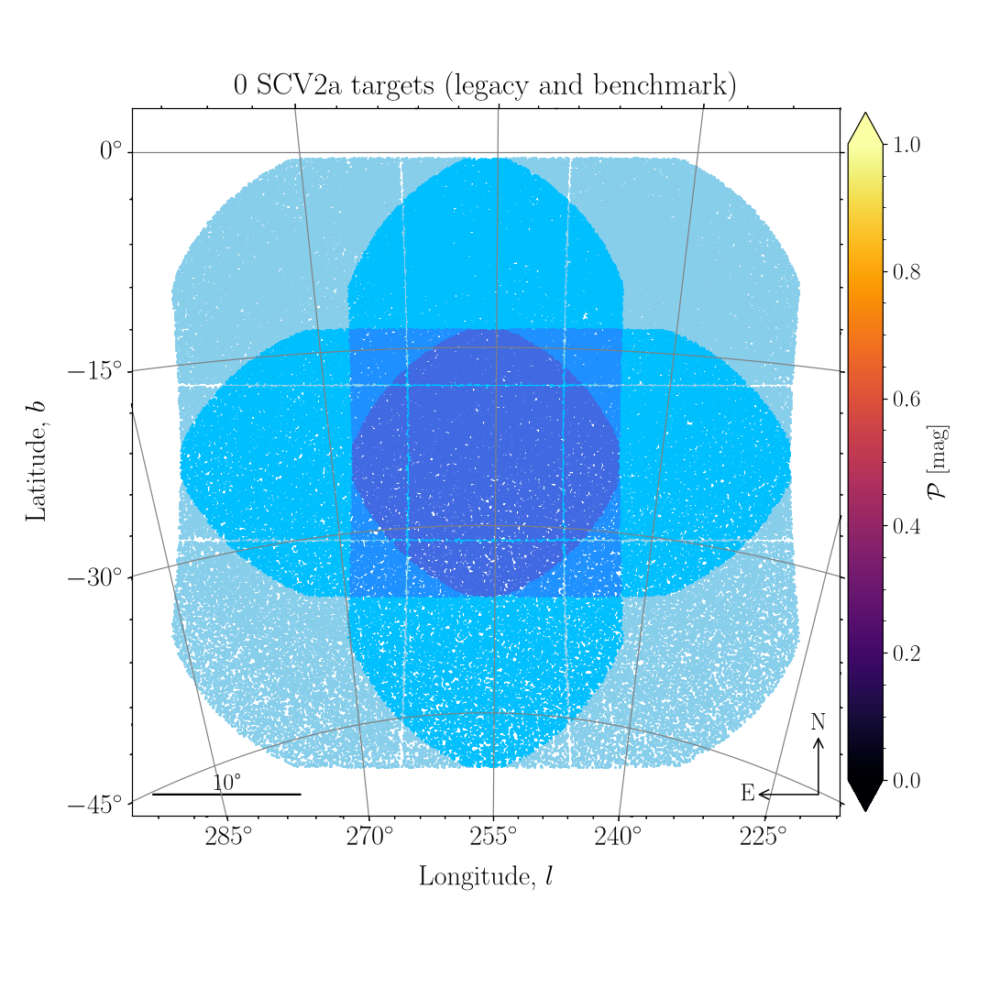

In [165]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 32 == 32]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=50, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV2a targets (legacy and benchmark)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV2a.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV2b` sample (legacy and benchmark):

<IPython.core.display.Javascript object>


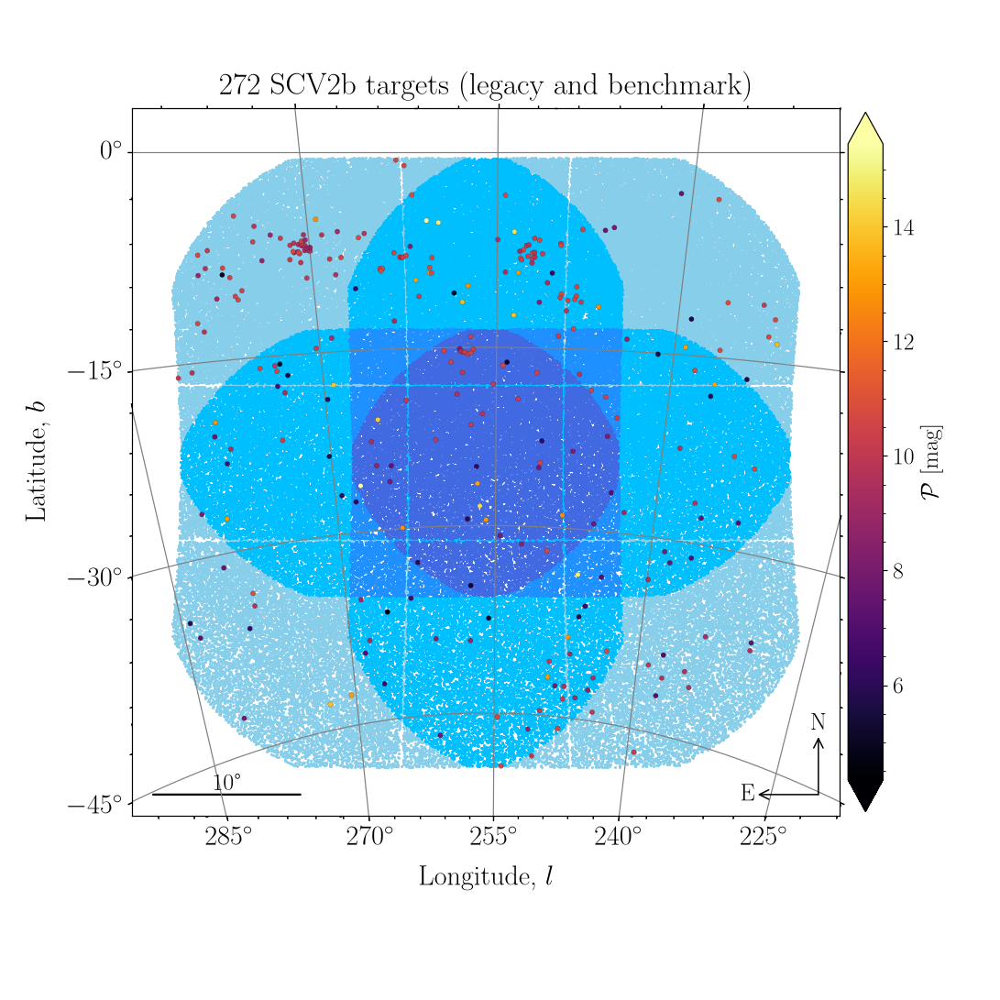

In [166]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 64 == 64]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=50, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV2b targets (legacy and benchmark)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV2b.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV3a` sample (photometric stable):

<IPython.core.display.Javascript object>


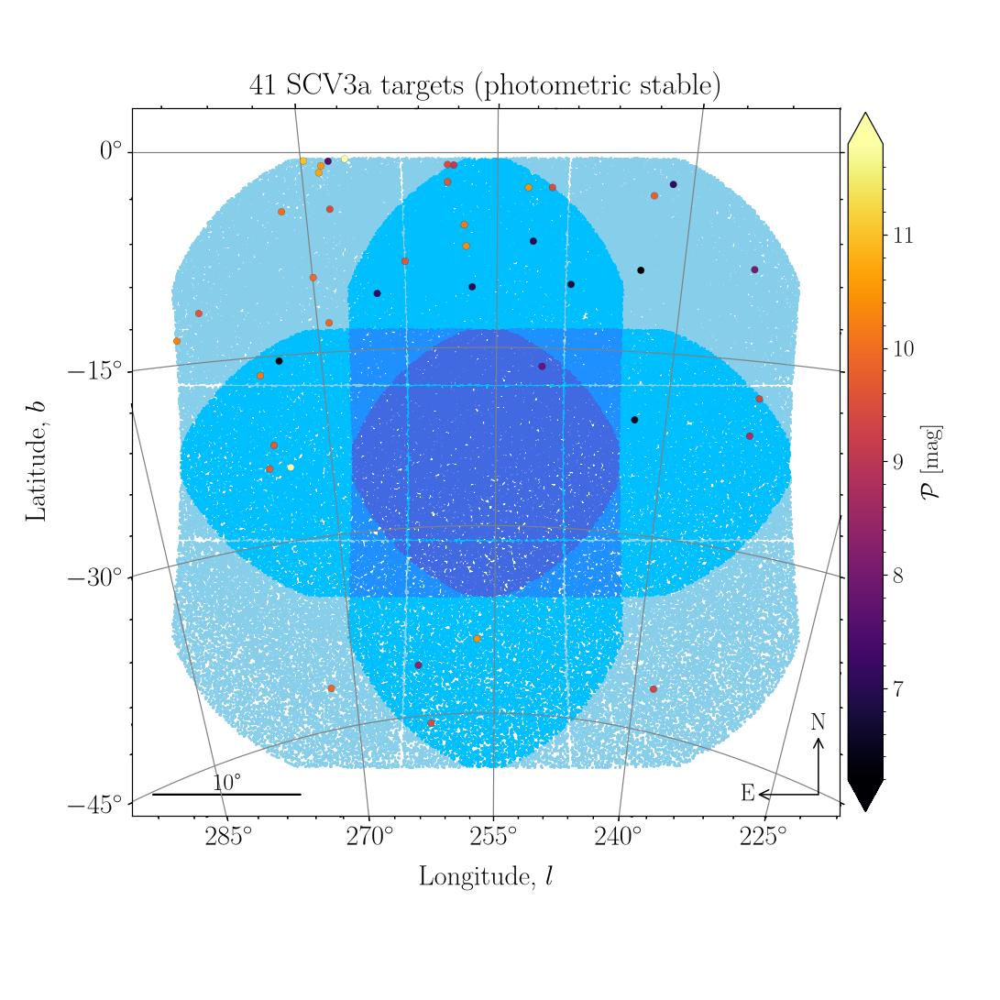

In [167]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 128 == 128]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV3a targets (photometric stable)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV3a.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV3b` sample (photometric stable):

<IPython.core.display.Javascript object>


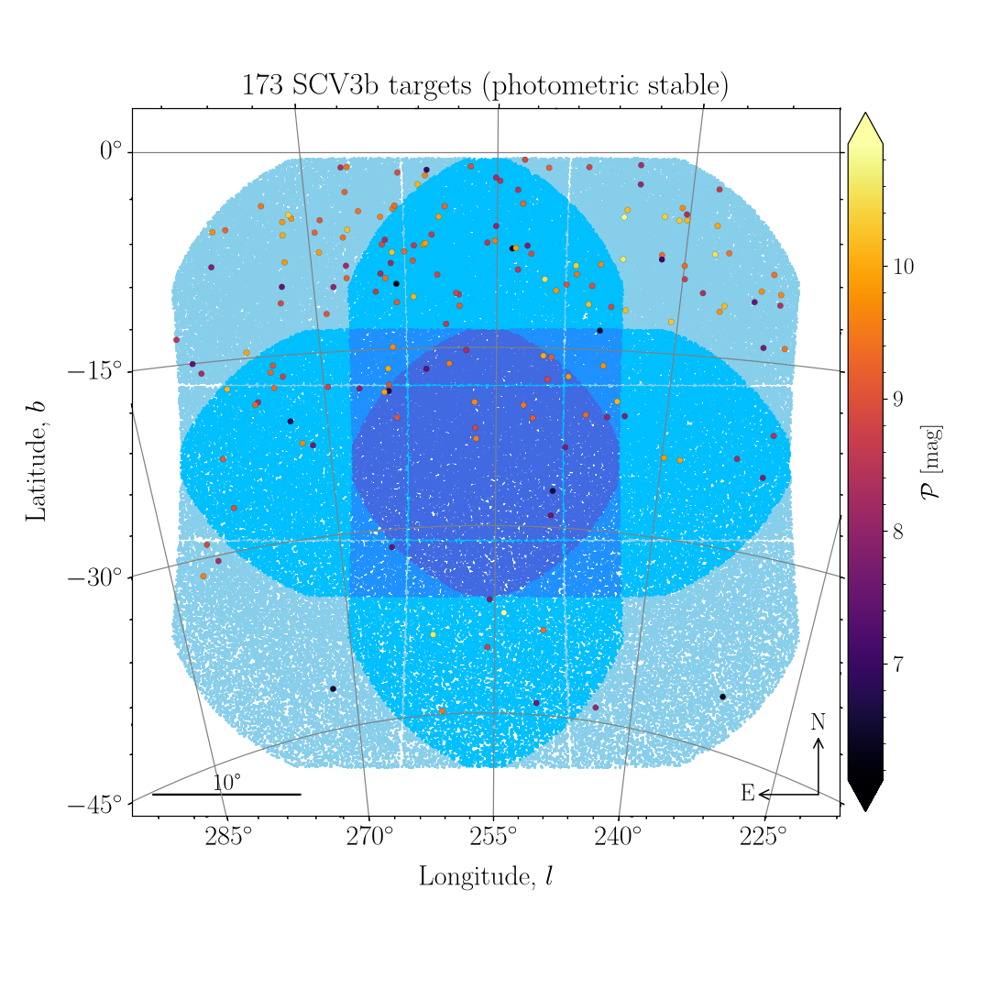

In [168]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 256 == 256]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=70, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV3b targets (photometric stable)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV3b.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV4a` sample (solar-like pulsators):

<IPython.core.display.Javascript object>


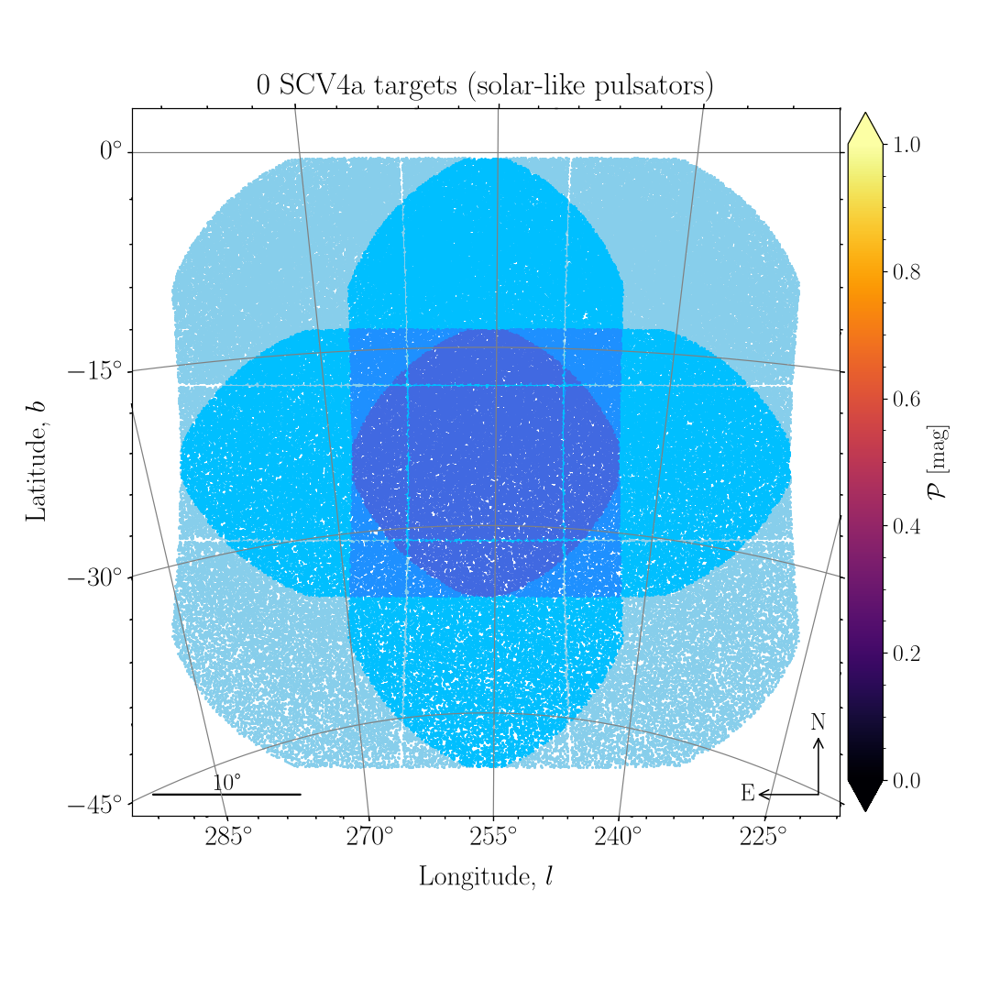

In [169]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 512 == 512]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=70, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV4a targets (solar-like pulsators)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV4a.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV4b` sample (solar-like pulsators):

<IPython.core.display.Javascript object>


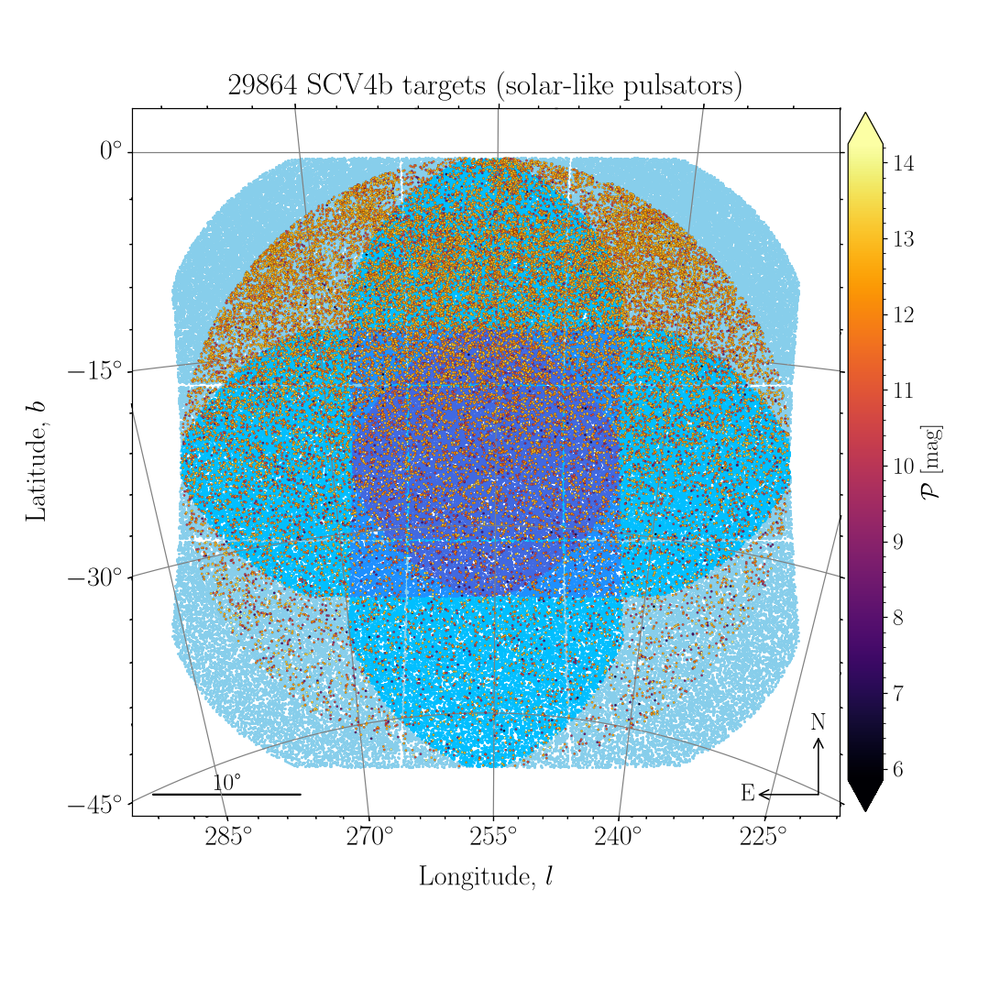

In [170]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 1024 == 1024]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=10, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV4b targets (solar-like pulsators)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV4b.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV5` sample (gamma Dor pulsators):

<IPython.core.display.Javascript object>


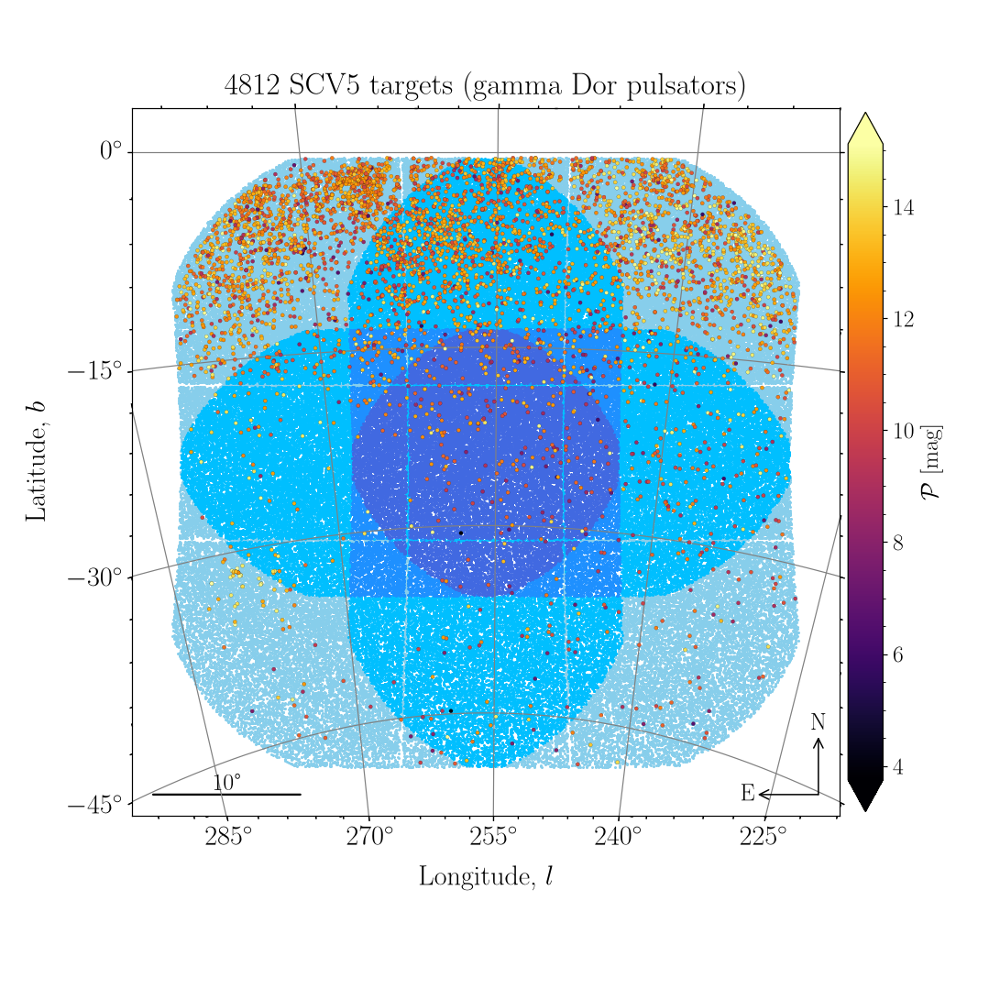

In [171]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 2048 == 2048]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=30, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV5 targets (gamma Dor pulsators)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV5.png', bbox_inches='tight', dpi=200)

Plot scvPIC `SCV6` sample (transiting exoplanets):

<IPython.core.display.Javascript object>


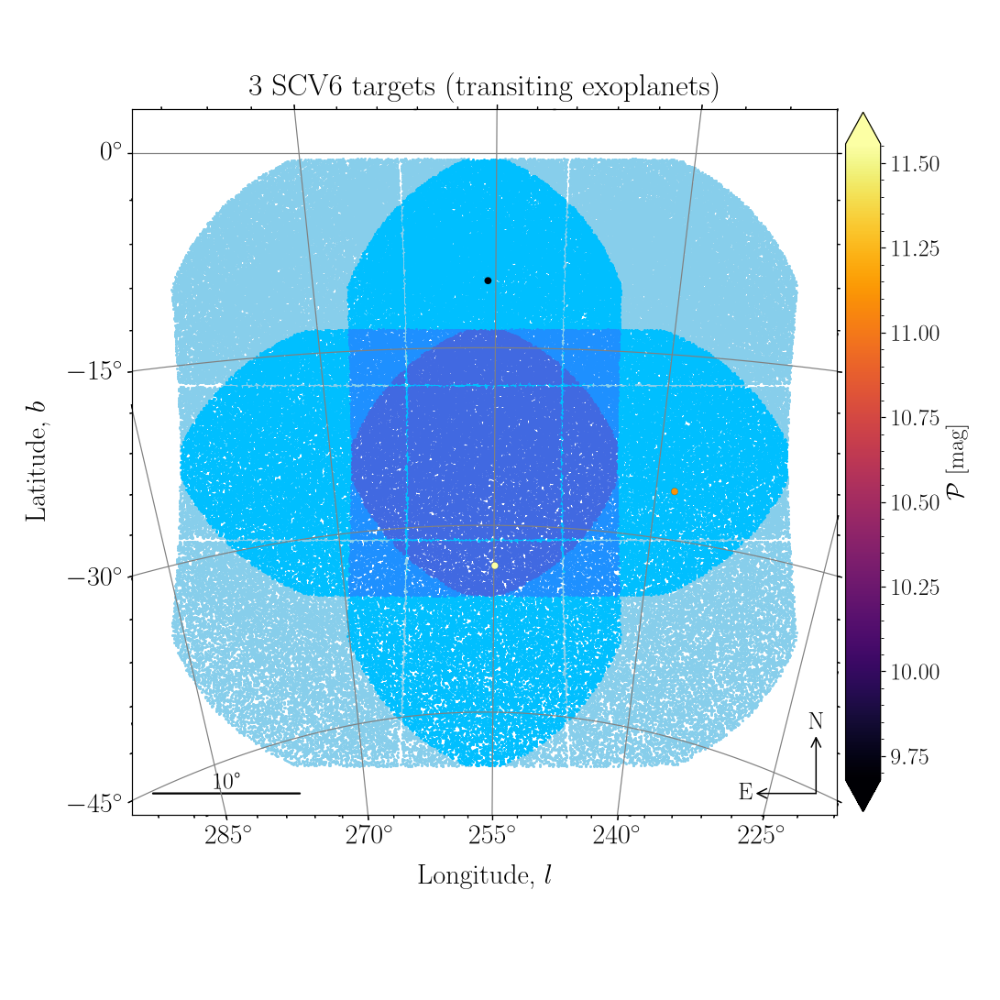

In [172]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['scvPIC'] & 4096 == 4096]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=100, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} SCV6 targets (transiting exoplanets)'
)
fig.savefig('skymap_LOPS2_scvPIC2101_SCV6.png', bbox_inches='tight', dpi=200)

Lastly, we show all targets without (red) giants. The reason being that we have found that this catalogue is faulty and thus it I (Nicholas) reported it to the scvPIC working group. It should be solved for the next release of PIC 2.2.0.1. Here is the issue:

<IPython.core.display.Javascript object>


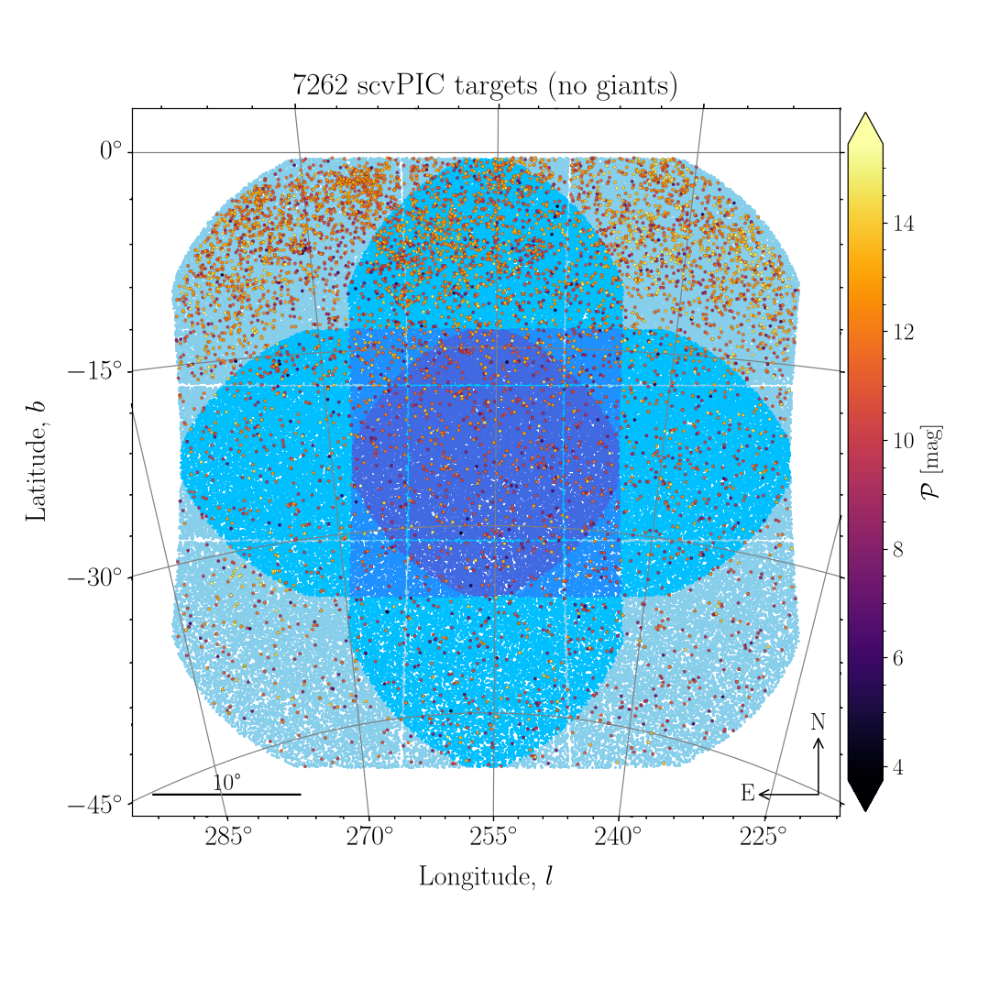

In [173]:
dx = dt[(dt.ncams != 0)]
dx = dx.loc[dx['source'] & 32 == 32]
dx = dx[(dx.case != 4) & (dx.case != 6) & (dx.case != 10) & 
        (dx.case != 12) & (dx.case != 16) & (dx.case != 18)]
fig, ax = pt.plotPlatoFOV(
    # Plot skymap
    'LOPS2', system='galactic', fovSize=30, ncamStars=dt0,
    # Plot stars
    raStars=dx.ra, decStars=dx.dec, c=dx.Pmag, s=20, 
    cmap='inferno', clabel=r'$\mathcal{P}$ [mag]', 
    # Settings
    figsize=(10,10), title=f'{dx.shape[0]} scvPIC targets (no giants)'
)